# Way2Agribusiness — 12-Month Average Monthly Price Forecasting

**Assignment:** Internship Task — Django, FastAPI and AI-ML
**Deliverable:** one reproducible notebook that cleans the supplied monthly price data, compares forecasting models with chronological validation, forecasts the next 12 months, and answers all nine assignment questions.

## Objectives
1. Clean the data (missing values, duplicates, outliers, anomalies) without deleting legitimate price shocks.
2. Compare baselines and candidate models using rolling-origin validation; keep the final 12 months untouched until selection is finished.
3. Evaluate with MAE, RMSE, WAPE, sMAPE and MAPE, on training, validation and an untouched test period.
4. Forecast 12 months with empirical prediction intervals.
5. Answer the nine questions, including Django / FastAPI / Next.js / React Native deployment and production monitoring.

## How to read this notebook
* Every number printed below comes from code that was **actually executed** on the supplied `price_data.csv`. Nothing is hard-coded.
* Sections that describe deployment code (Django, FastAPI, Next.js, React Native) contain **representative code that is not executed inside this notebook**. The testing section lists exactly which tests ran and which did not.
* Only `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib` and `joblib` are needed, so it runs comfortably on a CPU-only Windows laptop (a GPU is not used).

## 1. Environment setup

**Inputs:** none. **Outputs:** imported libraries, global configuration, a fixed random seed.
**Assumptions:** Python 3.10+. To rebuild the environment from a fresh machine (Windows PowerShell):

```
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements.txt
jupyter lab
```

The configuration cell is the only place you should edit paths. If `price_data.csv` is not found, the notebook stops with an explicit message instead of substituting synthetic data.

In [1]:
# Standard-library helpers: timing, platform info, JSON, warnings, random, paths.
import time
import sys
import platform
import json
import random
import warnings
from datetime import datetime, timezone
from pathlib import Path
from typing import Callable, Dict, List, Optional, Tuple

# NumPy provides fast numerical arrays and math used throughout.
import numpy as np

# pandas loads, cleans and transforms the tabular / time-series data.
import pandas as pd

# Matplotlib draws every chart in the notebook.
import matplotlib
import matplotlib.pyplot as plt

# SciPy's optimizer estimates the smoothing parameters of exponential-smoothing models.
import scipy
from scipy.optimize import minimize

# scikit-learn supplies the regression models and preprocessing used by the ML candidates.
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# joblib serialises the model artifact so a web service can reload it.
import joblib

# Record the notebook start time so the final runtime summary is accurate.
NOTEBOOK_START = time.perf_counter()

# Fix random seeds so every re-run gives identical results.
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Keep the output readable: hide non-actionable library warnings, show wide tables.
warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
# ---- CONFIGURATION (edit here only) ----------------------------------------
# Candidate locations for the CSV; the first one that exists is used.
DATA_CANDIDATES = ["price_data.csv", "data/price_data.csv", "/mnt/user-data/uploads/price_data.csv"]

# Leave as None to auto-detect the date and price columns; set explicitly if detection is ambiguous.
DATE_COL: Optional[str] = None
TARGET_COL: Optional[str] = None

# Forecast horizon requested by the assignment (months).
HORIZON = 12

# Number of final months held out as an untouched test set (never used for tuning or selection).
TEST_MONTHS = 12

# Smallest training window (months) used in the first rolling-origin fold.
MIN_TRAIN_MONTHS = 120

# Spacing (months) between consecutive rolling-origin forecast origins.
ORIGIN_STEP = 3

# Output folder for forecast CSV, model artifact and figures.
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | scipy 1.17.1


## 2. Dataset loading and validation

The PDF's data dictionary (`price_data.txt`) defines two fields: `date` (ISO 8601, `YYYY-MM-DD`) and `avg_monthly_price` (average monthly price). The code below locates the file, **auto-identifies** the date and price columns, and **refuses to guess** if the result is ambiguous. It then prints shape, dtypes, date range, inferred frequency, missing values, duplicates and descriptive statistics.

In [3]:
def locate_dataset(candidates: List[str]) -> Path:
    """Return the first existing path from `candidates`, otherwise raise a clear error."""
    # Check each configured location in order.
    for candidate in candidates:
        if Path(candidate).exists():
            return Path(candidate)
    # Stop explicitly: the notebook never substitutes a synthetic dataset.
    raise FileNotFoundError(
        f"price_data.csv not found in {candidates}. Place the assignment CSV next to the notebook "
        "or add its path to DATA_CANDIDATES. No synthetic data will be substituted."
    )


def identify_columns(df: pd.DataFrame, date_col: Optional[str], target_col: Optional[str]) -> Tuple[str, str]:
    """Identify the date column and the numeric price column; raise if ambiguous."""
    # Honour explicit user overrides first.
    if date_col and target_col:
        return date_col, target_col
    date_candidates, numeric_candidates = [], []
    for col in df.columns:
        series = df[col]
        # Numeric columns are price candidates (never parsed as dates, which would misread integers as epochs).
        if pd.api.types.is_numeric_dtype(series):
            numeric_candidates.append(col)
            continue
        # Text columns whose values mostly parse as dates are date candidates.
        parsed = pd.to_datetime(series, errors="coerce")
        if parsed.notna().mean() >= 0.9:
            date_candidates.append(col)
        # Text columns that are mostly numbers (e.g. "5,500") are price candidates.
        elif pd.to_numeric(series, errors="coerce").notna().mean() >= 0.9:
            numeric_candidates.append(col)
    # Ambiguity must be resolved by a human, not guessed.
    if len(date_candidates) != 1 or len(numeric_candidates) != 1:
        raise ValueError(
            f"Ambiguous columns: date candidates={date_candidates}, numeric candidates={numeric_candidates}. "
            "Set DATE_COL and TARGET_COL in the configuration cell."
        )
    return date_candidates[0], numeric_candidates[0]


# Locate and read the raw file exactly as supplied (no transformations yet).
DATA_PATH = locate_dataset(DATA_CANDIDATES)
raw_df = pd.read_csv(DATA_PATH)

# Identify the columns, falling back to the configured overrides if provided.
DATE_COL, TARGET_COL = identify_columns(raw_df, DATE_COL, TARGET_COL)
print(f"Data file : {DATA_PATH}")
print(f"Date column: {DATE_COL!r} | Target column: {TARGET_COL!r}")

Data file : price_data.csv
Date column: 'date' | Target column: 'avg_monthly_price'


In [4]:
# Basic schema inspection of the raw data.
print("Shape:", raw_df.shape)
print("Columns:", list(raw_df.columns))
print("Dtypes:\n", raw_df.dtypes.to_string())

# Missing values and exact duplicate counts before any cleaning.
print("\nMissing values per column:\n", raw_df.isna().sum().to_string())
print("Duplicate rows:", int(raw_df.duplicated().sum()), "| duplicate dates:", int(raw_df[DATE_COL].duplicated().sum()))

# Parse dates only for the inspection (the formal cleaning step comes next).
inspect_dates = pd.to_datetime(raw_df[DATE_COL], errors="coerce")
print("\nDate range:", inspect_dates.min().date(), "->", inspect_dates.max().date())

# Validate that the data is monthly: every date is a month start and consecutive gaps are one month.
sorted_dates = inspect_dates.sort_values()
print("All dates are the 1st of a month:", bool((sorted_dates.dt.day == 1).all()))
print("Inferred frequency:", pd.infer_freq(sorted_dates))

# Descriptive statistics of the raw target.
display(raw_df[TARGET_COL].describe().to_frame().T)
display(raw_df.head(5))
display(raw_df.tail(5))

Shape: (249, 2)
Columns: ['date', 'avg_monthly_price']
Dtypes:
 date                   str
avg_monthly_price    int64

Missing values per column:
 date                 0
avg_monthly_price    0
Duplicate rows: 0 | duplicate dates: 0

Date range: 2005-01-01 -> 2025-09-01
All dates are the 1st of a month: True
Inferred frequency: MS


,count,mean,std,min,25%,50%,75%,max
avg_monthly_price,249.0,7918.891566,2804.992684,3500.0,6123.0,7250.0,9783.0,16163.0


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


,date,avg_monthly_price
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750


## 3. Data cleaning

**Policy (applied transparently and reported):**

| Issue | Policy | Why |
|---|---|---|
| Unparseable dates | drop the row, count it | a price without a month cannot be placed on the time axis |
| Non-numeric / non-positive prices | set to missing, count them | a price ≤ 0 is invalid for a market price and breaks log transforms |
| Duplicate months | aggregate by **mean** | an "average monthly price" duplicated for one month is best reconciled by averaging |
| Missing months | rebuild a regular month-start index; interpolate (time-based) only gaps ≤ 3 months and flag them | avoids long fabricated stretches |
| Outliers | **flag, inspect, keep** unless demonstrably invalid | real price shocks are signal; deleting them would make forecasts overconfident |

The cleaning logic is a function so that it can be reused in the production service and unit-tested.

In [5]:
def clean_monthly_series(
    raw: pd.DataFrame, date_col: str, price_col: str, max_gap_fill: int = 3
) -> Tuple[pd.Series, pd.Series, Dict[str, int]]:
    """Clean raw (date, price) rows into a regular month-start price series.

    Returns (price_series, imputed_mask, report). `imputed_mask` is True where a value was interpolated.
    """
    report: Dict[str, int] = {"rows_raw": int(len(raw))}
    frame = raw[[date_col, price_col]].copy()
    # Parse ISO-8601 dates; invalid strings become NaT instead of raising.
    frame["date"] = pd.to_datetime(frame[date_col], errors="coerce")
    # Convert prices to numbers; malformed text becomes NaN.
    frame["price"] = pd.to_numeric(frame[price_col], errors="coerce")
    report["invalid_dates"] = int(frame["date"].isna().sum())
    report["malformed_or_missing_prices"] = int(frame["price"].isna().sum())
    # A non-positive market price is impossible, so treat it as missing.
    non_positive = frame["price"] <= 0
    report["non_positive_prices"] = int(non_positive.sum())
    frame.loc[non_positive, "price"] = np.nan
    # Drop rows without a usable date.
    frame = frame.dropna(subset=["date"])
    # Snap every date to its month start so "2020-03-15" and "2020-03-01" are the same month.
    frame["month"] = frame["date"].dt.to_period("M").dt.to_timestamp()
    report["duplicate_months"] = int(frame["month"].duplicated().sum())
    # Reconcile duplicate months by averaging (NaNs are skipped by mean).
    monthly = frame.groupby("month")["price"].mean().sort_index()
    # Build the complete month-start index between first and last observation.
    full_index = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS", name="date")
    series = monthly.reindex(full_index)
    report["missing_months_before_fill"] = int(series.isna().sum())
    # Interpolate only short interior gaps; longer gaps stay NaN so they are visible, not hidden.
    filled = series.interpolate(method="time", limit=max_gap_fill, limit_area="inside")
    imputed_mask = series.isna() & filled.notna()
    report["imputed_months"] = int(imputed_mask.sum())
    report["unresolved_missing_months"] = int(filled.isna().sum())
    report["rows_clean"] = int(len(filled))
    filled.name = "price"
    return filled, imputed_mask, report


# Run the cleaning on the real dataset.
price, imputed_mask, clean_report = clean_monthly_series(raw_df, DATE_COL, TARGET_COL)

# The model pipeline needs a gap-free series; stop loudly if cleaning could not guarantee that.
assert price.isna().sum() == 0, "Unresolved missing months remain - inspect before modelling."
assert price.index.is_monotonic_increasing and price.index.is_unique
print(json.dumps(clean_report, indent=2))
print("Series:", price.index.min().date(), "->", price.index.max().date(), "| n =", len(price))

{
  "rows_raw": 249,
  "invalid_dates": 0,
  "malformed_or_missing_prices": 0,
  "non_positive_prices": 0,
  "duplicate_months": 0,
  "missing_months_before_fill": 0,
  "imputed_months": 0,
  "unresolved_missing_months": 0,
  "rows_clean": 249
}
Series: 2005-01-01 -> 2025-09-01 | n = 249


### Outlier and anomaly screening

We use a **robust z-score on monthly log-returns** (median / MAD instead of mean / standard deviation, so extreme values do not mask themselves). A month is *flagged* when |robust z| > 3.5. Flagged months are then inspected in context (previous and next prices, and whether the move reverses) to separate **genuine shocks** from **likely data-entry errors**. We also check for *stale repeated values* (the same price in consecutive months), which can indicate carried-forward data.

In [6]:
def detect_outliers(series: pd.Series, threshold: float = 3.5) -> pd.DataFrame:
    """Flag months whose log-return has a robust z-score above `threshold`."""
    # Month-over-month log-return: scale-free and comparable across the 2005-2025 price levels.
    log_return = np.log(series).diff()
    # Median and MAD are robust to the very outliers we are trying to find.
    median = log_return.median()
    mad = (log_return - median).abs().median()
    # 0.6745 rescales MAD so the score is comparable to a normal z-score.
    robust_z = 0.6745 * (log_return - median) / mad
    out = pd.DataFrame({"price": series, "prev_price": series.shift(1), "next_price": series.shift(-1),
                        "log_return": log_return, "robust_z": robust_z})
    out["flagged"] = out["robust_z"].abs() > threshold
    # A "reversal" means the next month undoes more than half of the jump: typical of a typo or one-off spike.
    jump = series - series.shift(1)
    out["reverses_next_month"] = (series.shift(-1) - series) * jump < 0
    out["reversal_share"] = ((series.shift(-1) - series) / jump).abs()
    return out


outlier_table = detect_outliers(price)
flagged = outlier_table[outlier_table["flagged"]]
print(f"Flagged months (|robust z| > 3.5): {len(flagged)} of {len(price)}")
display(flagged.round(3))

# Stale repeats: identical consecutive prices.
repeats = price[price.diff() == 0]
print(f"\nMonths where price equals the previous month: {len(repeats)}")
display(repeats.to_frame())
print("Smallest / largest price:", price.min(), price.max(), "| any non-positive:", bool((price <= 0).any()))

Flagged months (|robust z| > 3.5): 14 of 249

Months where price equals the previous month: 9
Smallest / largest price: 3500.0 16163.0 | any non-positive: False


,price,prev_price,next_price,log_return,robust_z,flagged,reverses_next_month,reversal_share
date,,,,,,,,
2005-06-01,5058.0,5876.0,4919.0,-0.150,-3.540,True,False,0.170
2005-12-01,3813.0,4665.0,4000.0,-0.202,-4.763,True,True,0.219
2006-02-01,4755.0,4000.0,4176.0,0.173,4.084,True,True,0.767
2006-04-01,3500.0,4176.0,6000.0,-0.177,-4.171,True,True,3.698
2006-05-01,6000.0,3500.0,4964.0,0.539,12.730,True,True,0.414
2006-06-01,4964.0,6000.0,4632.0,-0.190,-4.477,True,False,0.320
2009-08-01,6964.0,8106.0,6940.0,-0.152,-3.586,True,False,0.021
2013-10-01,7744.0,6590.0,11016.0,0.161,3.811,True,False,2.835
2013-11-01,11016.0,7744.0,10670.0,0.352,8.324,True,True,0.106


,price
date,
2018-09-01,7200.0
2018-10-01,7200.0
2020-02-01,10188.0
2020-08-01,9725.0
2021-05-01,10863.0
2024-05-01,15863.0
2025-02-01,11313.0
2025-05-01,14263.0
2025-06-01,14263.0


In [7]:
# Decision rule, applied programmatically so it is auditable:
#   REMOVE only if the value is demonstrably invalid (non-positive / non-numeric) -> already handled in cleaning.
#   KEEP flagged values whose size is plausible and which are not impossible; they are real market moves.
invalid_after_cleaning = int((price <= 0).sum() + price.isna().sum())
kept_flagged = int(flagged.shape[0])
removed_values = 0
print(f"Invalid values remaining after cleaning : {invalid_after_cleaning}")
print(f"Flagged but kept as genuine shocks      : {kept_flagged}")
print(f"Values removed or winsorised            : {removed_values}")

# Show how extreme each flagged move is relative to a typical month, and whether it reversed.
if kept_flagged:
    typical = outlier_table["log_return"].abs().median()
    for date, row in flagged.iterrows():
        print(f"  {date:%Y-%m}: price {row.price:,.0f} (prev {row.prev_price:,.0f}), move {row.log_return:+.1%}, "
              f"{abs(row.log_return)/typical:.1f}x the median monthly move, "
              f"next-month reversal share {row.reversal_share:.2f}")

Invalid values remaining after cleaning : 0
Flagged but kept as genuine shocks      : 14
Values removed or winsorised            : 0
  2005-06: price 5,058 (prev 5,876), move -15.0%, 5.2x the median monthly move, next-month reversal share 0.17
  2005-12: price 3,813 (prev 4,665), move -20.2%, 7.1x the median monthly move, next-month reversal share 0.22
  2006-02: price 4,755 (prev 4,000), move +17.3%, 6.1x the median monthly move, next-month reversal share 0.77
  2006-04: price 3,500 (prev 4,176), move -17.7%, 6.2x the median monthly move, next-month reversal share 3.70
  2006-05: price 6,000 (prev 3,500), move +53.9%, 18.9x the median monthly move, next-month reversal share 0.41
  2006-06: price 4,964 (prev 6,000), move -19.0%, 6.6x the median monthly move, next-month reversal share 0.32
  2009-08: price 6,964 (prev 8,106), move -15.2%, 5.3x the median monthly move, next-month reversal share 0.02
  2013-10: price 7,744 (prev 6,590), move +16.1%, 5.7x the median monthly move, next-mont

In [8]:
# Before-and-after data quality report.
quality = pd.DataFrame({
    "metric": ["rows", "unparseable dates", "malformed / missing prices", "non-positive prices", "duplicate months",
               "missing months (regular index)", "months imputed", "unresolved missing", "flagged outliers", "values removed"],
    "before_cleaning": [clean_report["rows_raw"], clean_report["invalid_dates"], clean_report["malformed_or_missing_prices"],
                        clean_report["non_positive_prices"], clean_report["duplicate_months"],
                        clean_report["missing_months_before_fill"], 0, "n/a", "n/a", 0],
    "after_cleaning": [clean_report["rows_clean"], 0, 0, 0, 0, clean_report["unresolved_missing_months"],
                       clean_report["imputed_months"], clean_report["unresolved_missing_months"], kept_flagged, removed_values],
})
display(quality)

,metric,before_cleaning,after_cleaning
0,rows,249,249
1,unparseable dates,0,0
2,malformed / missing prices,0,0
3,non-positive prices,0,0
4,duplicate months,0,0
5,missing months (regular index),0,0
6,months imputed,0,0
7,unresolved missing,n/a,0
8,flagged outliers,n/a,14
9,values removed,0,0


## 4. Exploratory data analysis

We examine the level and trend, volatility, distribution, seasonality, autocorrelation and possible structural changes. These findings *drive* the model choices in later sections (e.g. whether seasonal models are worth including).

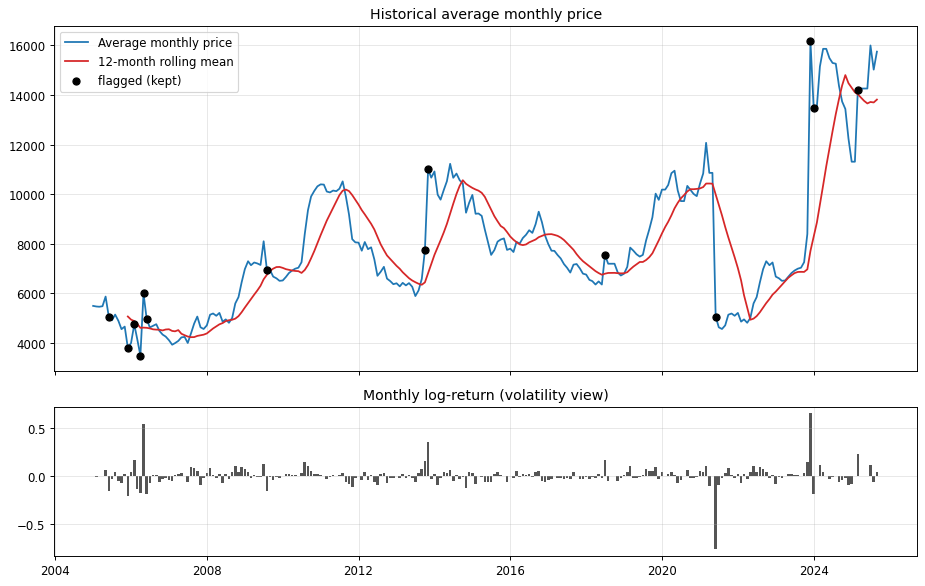

In [9]:
# Figure 1: price history with a 12-month rolling mean, and the monthly log-return below it.
log_returns = np.log(price).diff().dropna()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
axes[0].plot(price.index, price, label="Average monthly price", color="#1f77b4")
axes[0].plot(price.rolling(12).mean(), label="12-month rolling mean", color="#d62728")
# Mark flagged outliers so they are visible in context.
axes[0].scatter(flagged.index, flagged["price"], color="black", zorder=5, label="flagged (kept)")
axes[0].set_title("Historical average monthly price"); axes[0].legend()
axes[1].bar(log_returns.index, log_returns, width=25, color="#555")
axes[1].set_title("Monthly log-return (volatility view)")
plt.tight_layout(); plt.show()

In [10]:
# Annual summary: level, growth and volatility by calendar year (shows trend and regime changes).
annual = price.groupby(price.index.year).agg(mean_price="mean", min_price="min", max_price="max")
annual["yoy_growth_%"] = annual["mean_price"].pct_change() * 100
annual["monthly_volatility_%"] = log_returns.groupby(log_returns.index.year).std() * 100
display(annual.round(1))

# Era comparison: has the average monthly drift or volatility shifted across five-year blocks?
eras = pd.cut(log_returns.index.year, bins=[2004, 2009, 2014, 2019, 2025], labels=["2005-09", "2010-14", "2015-19", "2020-25"])
era_table = log_returns.groupby(eras).agg(mean_monthly_return_pct=lambda s: s.mean() * 100,
                                          volatility_pct=lambda s: s.std() * 100)
display(era_table.round(2))

,mean_price,min_price,max_price,yoy_growth_%,monthly_volatility_%
date,,,,,
2005,5072.5,3813.0,5876.0,NaN,8.2
2006,4548.8,3500.0,6000.0,-10.3,19.4
2007,4339.9,3935.0,5070.0,-4.6,5.7
2008,5244.5,4715.0,6450.0,20.8,5.3
2009,7070.7,6510.0,8106.0,34.8,6.7
2010,8031.2,6525.0,10320.0,13.6,4.4
2011,9778.8,8062.0,10520.0,21.8,4.2
2012,7251.0,6375.0,8075.0,-25.9,4.3
2013,7181.9,5896.0,11016.0,-1.0,11.4


,mean_monthly_return_pct,volatility_pct
2005-09,0.29,10.35
2010-14,0.66,6.96
2015-19,0.02,4.56
2020-25,0.69,13.70


Level skew: 0.99 | log-return skew: 0.05 | log-return excess kurtosis: 27.17


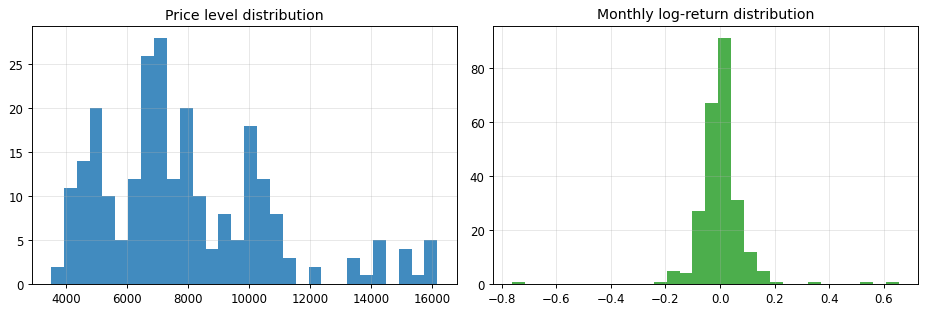

In [11]:
# Figure 2: distributions of the price level and of monthly log-returns.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(price, bins=30, color="#1f77b4", alpha=0.85); axes[0].set_title("Price level distribution")
axes[1].hist(log_returns, bins=30, color="#2ca02c", alpha=0.85); axes[1].set_title("Monthly log-return distribution")
plt.tight_layout(); plt.show()

# Skewness / kurtosis help decide whether to model in logs and how heavy-tailed shocks are.
print(f"Level skew: {price.skew():.2f} | log-return skew: {log_returns.skew():.2f} | log-return excess kurtosis: {log_returns.kurt():.2f}")

Seasonal strength (variance explained by calendar month): 0.045
Average deviation by month (%): {1: 0.3, 2: -0.4, 3: 1.9, 4: 0.2, 5: 3.3, 6: -3.2, 7: -4.2, 8: -3.1, 9: -1.1, 10: -0.1, 11: 0.3, 12: 1.4}


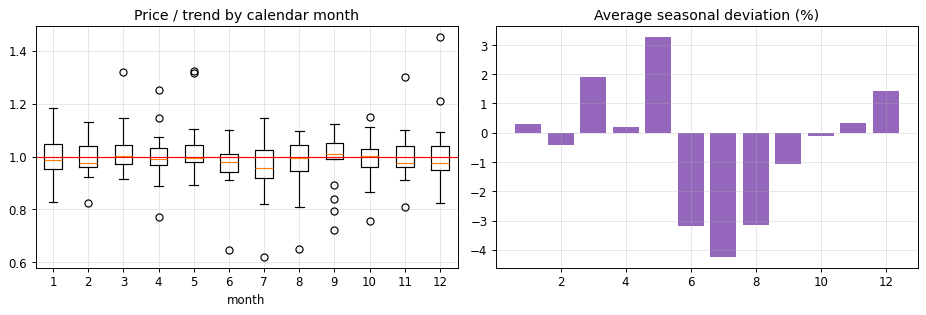

In [12]:
# Seasonality: divide each price by a centred 12-month moving average (removes the trend), then average by calendar month.
centred_trend = price.rolling(12, center=True).mean()
seasonal_ratio = (price / centred_trend).dropna()
month_profile = seasonal_ratio.groupby(seasonal_ratio.index.month).mean()

# Seasonal strength = share of variance in the detrended ratio explained by calendar month (0 = none, 1 = pure seasonality).
month_means = seasonal_ratio.groupby(seasonal_ratio.index.month).transform("mean")
seasonal_strength = 1 - ((seasonal_ratio - month_means).var() / seasonal_ratio.var())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].boxplot([seasonal_ratio[seasonal_ratio.index.month == m].values for m in range(1, 13)]); axes[0].set_xticklabels(range(1, 13))
axes[0].axhline(1, color="red", lw=1); axes[0].set_title("Price / trend by calendar month"); axes[0].set_xlabel("month")
axes[1].bar(month_profile.index, (month_profile - 1) * 100, color="#9467bd"); axes[1].set_title("Average seasonal deviation (%)")
plt.tight_layout(); plt.show()
print(f"Seasonal strength (variance explained by calendar month): {seasonal_strength:.3f}")
print("Average deviation by month (%):", ((month_profile - 1) * 100).round(1).to_dict())

Log-return ACF: lag-1 = -0.00; significant lags (95%): []
Log-price ACF at lag 12 = 0.42 (close to 1 => non-stationary level, use returns / differencing)
statsmodels not installed: formal ADF test skipped (the ACF evidence above is used instead).


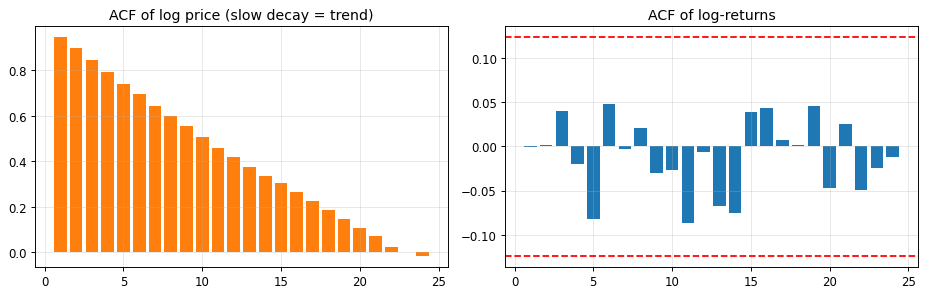

In [13]:
def autocorrelation(values: np.ndarray, max_lag: int) -> np.ndarray:
    """Sample autocorrelation for lags 1..max_lag (computed with NumPy, no extra packages)."""
    centred = values - values.mean()
    denominator = np.sum(centred ** 2)
    return np.array([np.sum(centred[lag:] * centred[:-lag]) / denominator for lag in range(1, max_lag + 1)])


# ACF of log-returns (differenced, roughly stationary) vs. ACF of the raw level (trending, non-stationary).
acf_returns = autocorrelation(log_returns.values, 24)
acf_level = autocorrelation(np.log(price).values, 24)
bound = 1.96 / np.sqrt(len(log_returns))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(1, 25), acf_level, color="#ff7f0e"); axes[0].set_title("ACF of log price (slow decay = trend)")
axes[1].bar(range(1, 25), acf_returns, color="#1f77b4")
axes[1].axhline(bound, color="red", ls="--"); axes[1].axhline(-bound, color="red", ls="--"); axes[1].set_title("ACF of log-returns")
plt.tight_layout(); plt.show()
significant = [lag for lag, v in enumerate(acf_returns, 1) if abs(v) > bound]
print(f"Log-return ACF: lag-1 = {acf_returns[0]:.2f}; significant lags (95%): {significant}")
print(f"Log-price ACF at lag 12 = {acf_level[11]:.2f} (close to 1 => non-stationary level, use returns / differencing)")

# Optional formal stationarity test (ADF) only if statsmodels happens to be installed; not required.
try:
    from statsmodels.tsa.stattools import adfuller
    print("ADF p-value (log price):", round(adfuller(np.log(price))[1], 4), "| (log-returns):", round(adfuller(log_returns)[1], 4))
except ImportError:
    print("statsmodels not installed: formal ADF test skipped (the ACF evidence above is used instead).")

### EDA conclusions that shape the modelling
The code above measures them; the model design uses them as follows:
* A strong **upward, non-stationary trend** (see annual table and ACF of the level) → forecast **log-returns / log-levels with trend-aware models**; seasonal-naive alone cannot extrapolate growth.
* The **seasonal strength** printed above decides whether Holt-Winters / SARIMA-style seasonal components are worth adding. If it is small, adding 12 seasonal parameters to ~250 noisy observations mostly adds variance, so seasonality is tested only via the **seasonal-naive baseline** and calendar features in the regression models.
* **Volatility differs across eras** (era table) → prediction intervals are calibrated empirically from out-of-sample errors rather than assuming constant variance.

## 5. Feature engineering and leakage prevention

The ML candidates predict the **next monthly log-return** `r_t = log(P_t) − log(P_{t−1})`, not the price level. Tree models cannot extrapolate a rising level beyond the range seen in training, whereas returns are roughly stationary, so this target is far more learnable.

**Features for forecasting month *t* (using only data up to month *t−1*):**

| Feature | Meaning |
|---|---|
| `r_lag1, r_lag2, r_lag3, r_lag6, r_lag12` | past returns (short memory and seasonal lag) |
| `momentum_12` | log-price change over the last 12 months |
| `gap_to_mean_12` | distance of the latest log price from its 12-month mean (mean reversion) |
| `vol_6, vol_12` | rolling standard deviation of returns |
| `month_sin, month_cos` | calendar month of the **target** month (known in advance, no leakage) |

**Leakage controls.** (1) `build_feature_row` receives only the history up to the forecast origin, so a feature can never see a future price. (2) The scaler lives inside a pipeline that is fitted on the training window of each fold only. (3) Splits are chronological. (4) For multi-step forecasts we use **recursive prediction**: the predicted return of month *t* is appended to the history to build the features for month *t+1* (this is how future lags are obtained).

In [14]:
# Names of the engineered features, in the exact order produced by build_feature_row.
FEATURE_NAMES = ["r_lag1", "r_lag2", "r_lag3", "r_lag6", "r_lag12", "momentum_12", "gap_to_mean_12",
                 "vol_6", "vol_12", "month_sin", "month_cos"]
# Minimum number of log-price observations needed to compute every feature.
MIN_FEATURE_HISTORY = 14


def build_feature_row(log_price_history: np.ndarray, target_month: int) -> np.ndarray:
    """Build the feature vector for the NEXT month using only `log_price_history` (no future information)."""
    # Monthly log-returns available at the forecast origin.
    r = np.diff(log_price_history)
    # Latest log price (the level at the origin).
    last = log_price_history[-1]
    return np.array([
        r[-1], r[-2], r[-3], r[-6], r[-12],                     # lagged returns
        last - log_price_history[-13],                           # 12-month momentum
        last - log_price_history[-12:].mean(),                   # gap to 12-month mean
        r[-6:].std(), r[-12:].std(),                             # recent volatility
        np.sin(2 * np.pi * target_month / 12), np.cos(2 * np.pi * target_month / 12),  # calendar encoding
    ])


def build_training_matrix(train: pd.Series) -> Tuple[np.ndarray, np.ndarray]:
    """Create (X, y) pairs; row for month t uses only prices before t."""
    log_p = np.log(train.values.astype(float))
    rows, targets = [], []
    # Start at index 14 so that every feature has enough history.
    for t in range(MIN_FEATURE_HISTORY, len(log_p)):
        rows.append(build_feature_row(log_p[:t], train.index[t].month))   # history strictly before month t
        targets.append(log_p[t] - log_p[t - 1])                           # the return we want to predict
    return np.vstack(rows), np.array(targets)


# Quick sanity check on shapes and on the absence of NaNs/infinities.
X_demo, y_demo = build_training_matrix(price)
print("Feature matrix:", X_demo.shape, "| target:", y_demo.shape, "| finite:", bool(np.isfinite(X_demo).all()))

Feature matrix: (235, 11) | target: (235,) | finite: True


## 6. Baselines and candidate models

Each model has the same interface `model(train_series, horizon, **params) -> np.ndarray` of price forecasts, which makes chronological validation, deployment and testing uniform. All work on the **log scale** where relevant (prices grew several-fold, so percentage changes are more stable than absolute changes).

| Candidate | Why it is included | Known limitation |
|---|---|---|
| **Naive** (last value) | The benchmark every model must beat | ignores trend |
| **Seasonal naive** (same month last year) | Tests whether seasonality is exploitable | ignores trend, noisy |
| **Moving average (12)** | Simple smoother benchmark | lags a trending series badly |
| **Drift** (random walk with average growth) | Strong, cheap benchmark for trending series | assumes constant growth |
| **Simple exponential smoothing (SES)** | Adaptive level, no trend | flat forecasts |
| **Damped-trend Holt (ETS A,Ad,N on logs)** | Adaptive level + trend whose growth fades with horizon (usually safest for 12-month horizons) | no seasonality |
| **Ridge regression on lags + calendar** | Interpretable, regularised, uses the engineered features | linear; recursive errors compound |
| **Gradient boosting (HistGradientBoosting)** on returns | Captures non-linear effects, justified by ~230 usable rows only if it validates well | can overfit small samples |

Holt–Winters / SARIMA are **not** included as separate candidates: seasonal strength was measured in the EDA and the seasonal-naive baseline directly tests whether seasonality carries any forecastable signal. (If you have `statsmodels`, they can be added to the registry below without touching the evaluation code.)

In [15]:
# ---------------- Baseline models (all return price-level forecasts) ----------------
def naive_forecast(train: pd.Series, horizon: int) -> np.ndarray:
    """Repeat the last observed price for every future month."""
    return np.repeat(float(train.iloc[-1]), horizon)


def seasonal_naive_forecast(train: pd.Series, horizon: int) -> np.ndarray:
    """Repeat the prices of the same calendar months from the last 12 observed months."""
    last_year = train.iloc[-12:].values.astype(float)
    # Tile the last year and cut to the requested horizon.
    return np.resize(last_year, horizon)


def moving_average_forecast(train: pd.Series, horizon: int, window: int = 12) -> np.ndarray:
    """Forecast the mean of the last `window` prices."""
    return np.repeat(float(train.iloc[-window:].mean()), horizon)


def drift_forecast(train: pd.Series, horizon: int, window: Optional[int] = None) -> np.ndarray:
    """Random walk with drift on the log scale; drift = average monthly log growth over `window` months (None = all)."""
    y = np.log(train.values.astype(float))
    span = (len(y) - 1) if window is None else min(window, len(y) - 1)
    slope = (y[-1] - y[-1 - span]) / span
    return np.exp(y[-1] + slope * np.arange(1, horizon + 1))

In [16]:
# ---------------- Exponential-smoothing family (own implementation: no statsmodels needed) ----------------
def _smoothing_filter(y: np.ndarray, alpha: float, beta: float, phi: float) -> Tuple[np.ndarray, float, float]:
    """Run damped-trend exponential smoothing over y; return one-step fitted values, final level and final trend."""
    level = y[0]
    # Initial trend = average monthly change in the first year of the training window.
    span = min(12, len(y) - 1)
    trend = (y[span] - y[0]) / span if beta > 0 else 0.0
    fitted = np.empty(len(y))
    fitted[0] = y[0]
    for t in range(1, len(y)):
        # One-step-ahead prediction from the state before seeing y[t].
        prediction = level + phi * trend
        fitted[t] = prediction
        # Update level and trend using the new observation.
        new_level = alpha * y[t] + (1 - alpha) * prediction
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return fitted, level, trend


def fit_smoothing(train: pd.Series, damped: bool) -> Dict[str, float]:
    """Estimate (alpha, beta, phi) by minimising one-step squared error on the log series."""
    y = np.log(train.values.astype(float))
    if damped:
        # Free parameters: alpha, beta, phi with sensible bounds (phi<1 damps the trend).
        objective = lambda p: np.sum((y[1:] - _smoothing_filter(y, p[0], p[1], p[2])[0][1:]) ** 2)
        result = minimize(objective, x0=[0.5, 0.1, 0.9], bounds=[(0.01, 0.99), (0.001, 0.5), (0.80, 0.98)], method="L-BFGS-B")
        alpha, beta, phi = result.x
    else:
        # SES: only alpha is free; no trend (beta=0, phi=0).
        objective = lambda p: np.sum((y[1:] - _smoothing_filter(y, p[0], 0.0, 0.0)[0][1:]) ** 2)
        result = minimize(objective, x0=[0.5], bounds=[(0.01, 0.99)], method="L-BFGS-B")
        alpha, beta, phi = result.x[0], 0.0, 0.0
    _, level, trend = _smoothing_filter(y, alpha, beta, phi)
    return {"alpha": float(alpha), "beta": float(beta), "phi": float(phi), "level": float(level), "trend": float(trend)}


def ses_forecast(train: pd.Series, horizon: int) -> np.ndarray:
    """Simple exponential smoothing: flat forecast at the smoothed level."""
    state = fit_smoothing(train, damped=False)
    return np.repeat(np.exp(state["level"]), horizon)


def damped_holt_forecast(train: pd.Series, horizon: int) -> np.ndarray:
    """Damped-trend Holt on log prices: trend contribution at horizon h is trend * (phi + phi^2 + ... + phi^h)."""
    state = fit_smoothing(train, damped=True)
    damping_sum = np.cumsum(state["phi"] ** np.arange(1, horizon + 1))
    return np.exp(state["level"] + damping_sum * state["trend"])

In [17]:
# ---------------- Machine-learning candidates (recursive multi-step forecasting) ----------------
def _make_regressor(kind: str, **params):
    """Create the scikit-learn estimator for 'ridge' or 'hgb'."""
    if kind == "ridge":
        # Standardise features inside the pipeline so the scaler is fitted only on training rows.
        return make_pipeline(StandardScaler(), Ridge(alpha=params.get("alpha", 10.0)))
    # Small, shallow boosted trees: appropriate for ~230 rows; fixed seed for reproducibility.
    return HistGradientBoostingRegressor(max_depth=params.get("max_depth", 2), learning_rate=params.get("learning_rate", 0.05),
                                         max_iter=params.get("max_iter", 100), l2_regularization=1.0,
                                         min_samples_leaf=10, random_state=SEED)


def ml_recursive_forecast(train: pd.Series, horizon: int, kind: str, **params) -> np.ndarray:
    """Fit on (features -> next log-return) using only `train`, then forecast recursively."""
    X, y = build_training_matrix(train)
    model = _make_regressor(kind, **params).fit(X, y)
    history = list(np.log(train.values.astype(float)))
    last_date = train.index[-1]
    prices = []
    for step in range(1, horizon + 1):
        # Calendar month of the month being predicted.
        target_month = (last_date + pd.DateOffset(months=step)).month
        # Features use the history INCLUDING earlier predicted months (recursive strategy).
        features = build_feature_row(np.array(history), target_month).reshape(1, -1)
        predicted_return = float(model.predict(features)[0])
        history.append(history[-1] + predicted_return)
        prices.append(np.exp(history[-1]))
    return np.array(prices)


def ridge_forecast(train: pd.Series, horizon: int, alpha: float = 10.0) -> np.ndarray:
    """Ridge regression on lag/calendar features, recursive multi-step."""
    return ml_recursive_forecast(train, horizon, "ridge", alpha=alpha)


def hgb_forecast(train: pd.Series, horizon: int, max_depth: int = 2, learning_rate: float = 0.05) -> np.ndarray:
    """Histogram gradient boosting on lag/calendar features, recursive multi-step."""
    return ml_recursive_forecast(train, horizon, "hgb", max_depth=max_depth, learning_rate=learning_rate)

In [18]:
# Registry: model name -> (function, small hyper-parameter grid). Grids are deliberately tiny (cost control).
MODEL_REGISTRY: Dict[str, Tuple[Callable, List[dict]]] = {
    "naive": (naive_forecast, [{}]),
    "seasonal_naive": (seasonal_naive_forecast, [{}]),
    "moving_average": (moving_average_forecast, [{"window": w} for w in (6, 12)]),
    "drift": (drift_forecast, [{"window": w} for w in (24, 60, None)]),
    "ses": (ses_forecast, [{}]),
    "damped_holt": (damped_holt_forecast, [{}]),
    "ridge_lags": (ridge_forecast, [{"alpha": a} for a in (1.0, 10.0, 100.0)]),
    "hist_gbm": (hgb_forecast, [{"max_depth": d, "learning_rate": lr} for d in (2, 3) for lr in (0.05, 0.1)]),
}
MIN_HISTORY = 24     # fewest observations accepted by the safe dispatcher below
MAX_HORIZON = 24     # longest horizon accepted (uncertainty beyond 2 years is not meaningful here)


def forecast_with(name: str, train: pd.Series, horizon: int, params: Optional[dict] = None) -> np.ndarray:
    """Validated entry point used by evaluation, tests and the production service."""
    # Reject unusable inputs early with explicit messages.
    if name not in MODEL_REGISTRY:
        raise KeyError(f"Unknown model '{name}'. Available: {sorted(MODEL_REGISTRY)}")
    if not (1 <= int(horizon) <= MAX_HORIZON):
        raise ValueError(f"horizon must be between 1 and {MAX_HORIZON}, got {horizon}")
    if len(train) < MIN_HISTORY:
        raise ValueError(f"Need at least {MIN_HISTORY} monthly observations, got {len(train)}")
    if name in ("ridge_lags", "hist_gbm") and len(train) < MIN_FEATURE_HISTORY + 24:
        raise ValueError("Not enough history to train the ML models reliably")
    if train.isna().any() or (train <= 0).any():
        raise ValueError("History contains missing or non-positive prices")
    forecast = MODEL_REGISTRY[name][0](train, int(horizon), **(params or {}))
    # Guard against numerical failures.
    if not np.isfinite(forecast).all():
        raise FloatingPointError(f"Model '{name}' produced non-finite forecasts")
    return forecast

## 7. Chronological validation design

```
|<----------------- development period (n − 12 months) ----------------->|<-- untouched test (12 m) -->|
|  train ... origin_1 ▶ 12-month forecast                                  |
|  train ........ origin_2 ▶ 12-month forecast                            |   (rolling-origin, step = 3 months)
```

* **Rolling-origin (expanding-window) validation:** at each origin the model is trained on all data up to that month and asked for the next 12 months; forecast windows never touch the test period.
* **Model selection and hyper-parameter tuning** use only these validation folds (lowest mean MAE).
* **Test period:** the final 12 months are used once, after selection, to estimate generalisation. Because the same validation folds both tune and select, validation scores are mildly optimistic; the untouched test is the honest check.
* **Metrics:** MAE (price units), RMSE (penalises large misses), WAPE (Σ|e|/Σ|actual|), sMAPE, and MAPE (safe here because every price is strictly positive).

In [19]:
def forecast_metrics(actual: np.ndarray, predicted: np.ndarray) -> Dict[str, float]:
    """Compute MAE, RMSE, MAPE, WAPE and sMAPE for aligned arrays (any shape)."""
    actual, predicted = np.asarray(actual, float).ravel(), np.asarray(predicted, float).ravel()
    error = actual - predicted
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAPE_%": float(np.mean(np.abs(error) / actual) * 100),       # valid: all actual prices > 0
        "WAPE_%": float(np.sum(np.abs(error)) / np.sum(np.abs(actual)) * 100),
        "sMAPE_%": float(np.mean(2 * np.abs(error) / (np.abs(actual) + np.abs(predicted))) * 100),
    }


def rolling_origin_forecasts(series: pd.Series, name: str, params: dict, origins: List[int], horizon: int
                             ) -> Tuple[np.ndarray, np.ndarray, float]:
    """Return (actual[fold, h], predicted[fold, h], seconds) for expanding-window origins."""
    start = time.perf_counter()
    actual_rows, predicted_rows = [], []
    for origin in origins:
        # Train strictly on data before the origin; the actuals are the next `horizon` months.
        train = series.iloc[:origin]
        actual_rows.append(series.iloc[origin:origin + horizon].values)
        predicted_rows.append(forecast_with(name, train, horizon, params))
    return np.array(actual_rows), np.array(predicted_rows), time.perf_counter() - start


# Split the cleaned series: development (validation) period vs the untouched test period.
n_obs = len(price)
dev_end = n_obs - TEST_MONTHS
dev_series, test_series = price.iloc[:dev_end], price.iloc[dev_end:]
# Origins are chosen so that every 12-month validation window ends before the test period starts.
VAL_ORIGINS = list(range(MIN_TRAIN_MONTHS, dev_end - HORIZON + 1, ORIGIN_STEP))
assert len(price) >= MIN_TRAIN_MONTHS + HORIZON + TEST_MONTHS, "Not enough history for the planned validation design"
print(f"Observations: {n_obs} | development: {len(dev_series)} ({dev_series.index[0]:%Y-%m} to {dev_series.index[-1]:%Y-%m})")
print(f"Test (untouched): {len(test_series)} months ({test_series.index[0]:%Y-%m} to {test_series.index[-1]:%Y-%m})")
print(f"Rolling-origin folds: {len(VAL_ORIGINS)} | first training size {VAL_ORIGINS[0]} | last window ends {dev_series.index[VAL_ORIGINS[-1] + HORIZON - 1]:%Y-%m}")

Observations: 249 | development: 237 (2005-01 to 2024-09)
Test (untouched): 12 months (2024-10 to 2025-09)
Rolling-origin folds: 36 | first training size 120 | last window ends 2024-09


In [20]:
# Tune every model's small grid on the validation folds only, and keep the best setting per model.
tuning_rows, best_by_model, validation_cache = [], {}, {}
for model_name, (_, grid) in MODEL_REGISTRY.items():
    best = None
    for params in grid:
        actual_mat, pred_mat, seconds = rolling_origin_forecasts(dev_series, model_name, params, VAL_ORIGINS, HORIZON)
        metrics = forecast_metrics(actual_mat, pred_mat)
        tuning_rows.append({"model": model_name, "params": str(params), **metrics, "seconds": seconds})
        if best is None or metrics["MAE"] < best["metrics"]["MAE"]:
            best = {"params": params, "metrics": metrics, "seconds": seconds}
            validation_cache[model_name] = (actual_mat, pred_mat)
    best_by_model[model_name] = best

tuning_table = pd.DataFrame(tuning_rows)
print("Full tuning log (every setting tried; validation folds only):")
display(tuning_table.round(2))

Full tuning log (every setting tried; validation folds only):


,model,params,MAE,RMSE,MAPE_%,WAPE_%,sMAPE_%,seconds
0,naive,{},1422.56,2514.38,17.83,17.62,16.75,0.01
1,seasonal_naive,{},2100.82,2990.90,28.49,26.02,25.61,0.01
2,moving_average,{'window': 6},1707.02,2667.10,22.27,21.15,20.62,0.01
3,moving_average,{'window': 12},1927.98,2799.94,25.42,23.88,23.32,0.01
4,drift,{'window': 24},1737.32,2846.83,22.78,21.52,20.95,0.01
5,drift,{'window': 60},1519.83,2628.22,19.30,18.83,18.05,0.01
6,drift,{'window': None},1450.90,2555.14,18.44,17.97,16.99,0.01
7,ses,{},1426.13,2509.22,17.90,17.67,16.84,0.15
8,damped_holt,{},1426.72,2509.66,17.91,17.67,16.85,0.83
9,ridge_lags,{'alpha': 1.0},1646.12,2708.36,21.92,20.39,19.22,0.77


In [21]:
# Model comparison table on validation (best setting per model), plus accuracy by horizon.
comparison = pd.DataFrame({
    name: {**info["metrics"], "best_params": str(info["params"]), "seconds": info["seconds"],
           "MAE_h1": float(np.mean(np.abs(validation_cache[name][0][:, 0] - validation_cache[name][1][:, 0]))),
           "MAE_h12": float(np.mean(np.abs(validation_cache[name][0][:, -1] - validation_cache[name][1][:, -1])))}
    for name, info in best_by_model.items()
}).T.sort_values("MAE")
for col in ["MAE", "RMSE", "MAPE_%", "WAPE_%", "sMAPE_%", "seconds", "MAE_h1", "MAE_h12"]:
    comparison[col] = comparison[col].astype(float).round(2)
print("Validation comparison (rolling-origin, 12-month horizon), sorted by MAE:")
display(comparison)

# Selection rule: lowest mean validation MAE. The test period plays no part here.
SELECTED_MODEL = comparison.index[0]
SELECTED_PARAMS = best_by_model[SELECTED_MODEL]["params"]
print(f"\nSelected on validation evidence: {SELECTED_MODEL} with params {SELECTED_PARAMS}")
naive_mae = comparison.loc["naive", "MAE"]
print(f"Validation MAE vs naive: {comparison.loc[SELECTED_MODEL, 'MAE']:.1f} vs {naive_mae:.1f} "
      f"({(1 - comparison.loc[SELECTED_MODEL, 'MAE'] / naive_mae) * 100:+.1f}% improvement)")

Validation comparison (rolling-origin, 12-month horizon), sorted by MAE:

Selected on validation evidence: naive with params {}
Validation MAE vs naive: 1422.6 vs 1422.6 (+0.0% improvement)


,MAE,RMSE,MAPE_%,WAPE_%,sMAPE_%,best_params,seconds,MAE_h1,MAE_h12
naive,1422.56,2514.38,17.83,17.62,16.75,{},0.01,288.33,2532.69
ses,1426.13,2509.22,17.90,17.67,16.84,{},0.15,299.18,2523.77
damped_holt,1426.72,2509.66,17.91,17.67,16.85,{},0.83,299.58,2524.57
drift,1450.90,2555.14,18.44,17.97,16.99,{'window': None},0.01,287.80,2593.74
ridge_lags,1560.77,2619.65,20.47,19.33,18.32,{'alpha': 100.0},0.82,291.33,2839.34
hist_gbm,1602.86,2742.15,21.15,19.86,18.43,"{'max_depth': 2, 'learning_rate': 0.05}",2.47,278.89,2881.29
moving_average,1707.02,2667.10,22.27,21.15,20.62,{'window': 6},0.01,702.36,2728.09
seasonal_naive,2100.82,2990.90,28.49,26.02,25.61,{},0.01,1730.67,2532.69


Best non-naive challenger: ses. It beats naive in 53% of 36 folds; fold-MAE std of selected model: 1593.2
Models within 1% of the best validation MAE (practically tied): ['naive', 'ses', 'damped_holt']
These differences are far smaller than the fold-to-fold spread, so ties are broken by simplicity (fewest parameters, no fitting): the selected model is the simplest of the tied group.


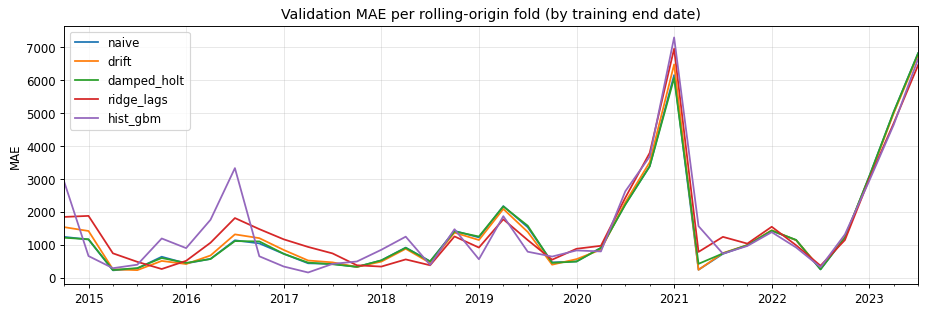

In [22]:
# Stability check: how consistent is the winner across folds? (A model that wins on average but fails in some eras is risky.)
fold_dates = [dev_series.index[o - 1] for o in VAL_ORIGINS]
fold_mae = pd.DataFrame({
    name: np.mean(np.abs(validation_cache[name][0] - validation_cache[name][1]), axis=1) for name in validation_cache
}, index=fold_dates)
fig, ax = plt.subplots(figsize=(11, 3.8))
fold_mae[["naive", "drift", "damped_holt", "ridge_lags", "hist_gbm"]].plot(ax=ax); ax.set_title("Validation MAE per rolling-origin fold (by training end date)"); ax.set_ylabel("MAE")
plt.tight_layout(); plt.show()

# Paired fold comparison: the best NON-naive challenger vs the naive benchmark (naive can never "beat" itself).
CHALLENGER = [m for m in comparison.index if m != "naive"][0]
win_rate = (fold_mae[CHALLENGER] < fold_mae["naive"]).mean() 
print(f"Best non-naive challenger: {CHALLENGER}. It beats naive in {win_rate:.0%} of {len(fold_mae)} folds; "
      f"fold-MAE std of selected model: {fold_mae[SELECTED_MODEL].std():.1f}")

# Tie check: models whose validation MAE is within 1% of the best are practically indistinguishable.
best_mae = comparison["MAE"].min()
tied = comparison.index[comparison["MAE"] <= best_mae * 1.01].tolist()
print(f"Models within 1% of the best validation MAE (practically tied): {tied}")
if len(tied) > 1:
    print("These differences are far smaller than the fold-to-fold spread, so ties are broken by simplicity "
          "(fewest parameters, no fitting): the selected model is the simplest of the tied group.")
else:
    print("No other model is within 1% of the best.")

## 8. Final evaluation on the untouched test period

Now each model (with its tuned settings) is trained on the **development period only** and asked to forecast the 12 held-out months. The ranking here is *reported for transparency*; it is **not** used to change the earlier selection. We also report **training (in-sample one-step-ahead)** errors for the selected model, which are expected to look better than out-of-sample errors and are **not** a measure of generalisation.

In [23]:
# Forecast the test months with every model trained on the development period only.
test_rows, test_predictions = [], {}
for model_name, info in best_by_model.items():
    pred = forecast_with(model_name, dev_series, HORIZON, info["params"])
    test_predictions[model_name] = pred
    test_rows.append({"model": model_name, **forecast_metrics(test_series.values, pred)})
test_table = pd.DataFrame(test_rows).set_index("model").sort_values("MAE").round(2)
test_table["selected"] = test_table.index == SELECTED_MODEL
print("Untouched test period results (12 months):")
display(test_table)
sel_test = forecast_metrics(test_series.values, test_predictions[SELECTED_MODEL])
nv_test = forecast_metrics(test_series.values, test_predictions["naive"])
print(f"Selected ({SELECTED_MODEL}) test MAE {sel_test['MAE']:.1f} vs naive {nv_test['MAE']:.1f} "
      f"| test rank by MAE: {list(test_table.index).index(SELECTED_MODEL) + 1} of {len(test_table)}")

Untouched test period results (12 months):
Selected (naive) test MAE 1160.3 vs naive 1160.3 | test rank by MAE: 2 of 8


,MAE,RMSE,MAPE_%,WAPE_%,sMAPE_%,selected
model,,,,,,
hist_gbm,1139.68,1525.01,8.94,8.25,8.38,False
naive,1160.33,1565.74,9.12,8.40,8.53,True
ses,1164.70,1568.81,9.15,8.43,8.56,False
damped_holt,1167.98,1570.25,9.18,8.45,8.58,False
drift,1217.93,1622.50,9.72,8.81,8.93,False
ridge_lags,1254.60,1683.74,10.06,9.08,9.18,False
moving_average,1711.78,2126.24,13.57,12.39,12.20,False
seasonal_naive,2296.42,2921.06,17.35,16.62,18.52,False


In [24]:
def fitted_one_step(name: str, train: pd.Series, params: dict) -> pd.Series:
    """In-sample one-step-ahead predictions (price scale) for the training window; used only for training metrics."""
    y = np.log(train.values.astype(float))
    if name == "naive":
        fitted = pd.Series(train.shift(1).values, index=train.index)
    elif name == "seasonal_naive":
        fitted = pd.Series(train.shift(12).values, index=train.index)
    elif name == "moving_average":
        fitted = train.shift(1).rolling(params["window"]).mean()
    elif name == "drift":
        w = params.get("window")
        slope = pd.Series(np.log(train.values), index=train.index).diff().rolling(w or len(train), min_periods=1).mean().shift(1)
        fitted = np.exp(pd.Series(y, index=train.index).shift(1) + slope)
    elif name in ("ses", "damped_holt"):
        s = fit_smoothing(train, damped=(name == "damped_holt"))
        fitted = pd.Series(np.exp(_smoothing_filter(y, s["alpha"], s["beta"], s["phi"])[0]), index=train.index)
    else:
        X, target = build_training_matrix(train)
        model = _make_regressor("ridge" if name == "ridge_lags" else "hgb", **params).fit(X, target)
        fitted = pd.Series(np.exp(y[MIN_FEATURE_HISTORY - 1:-1] + model.predict(X)), index=train.index[MIN_FEATURE_HISTORY:])
    return fitted.dropna()


# Training (in-sample, one-step-ahead) metrics for the selected model and the naive benchmark, on the development period.
rows = []
for name, params in dict.fromkeys([(SELECTED_MODEL, str(SELECTED_PARAMS)), ("naive", "{}")]) and {SELECTED_MODEL: SELECTED_PARAMS, "naive": {}}.items():
    fit = fitted_one_step(name, dev_series, params)
    rows.append({"model": name, "scope": "training (in-sample, 1-step)", **forecast_metrics(dev_series.loc[fit.index], fit)})
    rows.append({"model": name, "scope": "validation (rolling-origin, 12-step)", **best_by_model[name]["metrics"]})
    rows.append({"model": name, "scope": "test (untouched, 12-step)", **forecast_metrics(test_series.values, test_predictions[name])})
display(pd.DataFrame(rows).round(2))
print("Training one-step errors are NOT comparable with 12-step forecasting errors; they only show the model fits its own past.")

Training one-step errors are NOT comparable with 12-step forecasting errors; they only show the model fits its own past.


,model,scope,MAE,RMSE,MAPE_%,WAPE_%,sMAPE_%
0,naive,"training (in-sample, 1-step)",389.72,821.78,5.16,5.11,5.10
1,naive,"validation (rolling-origin, 12-step)",1422.56,2514.38,17.83,17.62,16.75
2,naive,"test (untouched, 12-step)",1160.33,1565.74,9.12,8.40,8.53


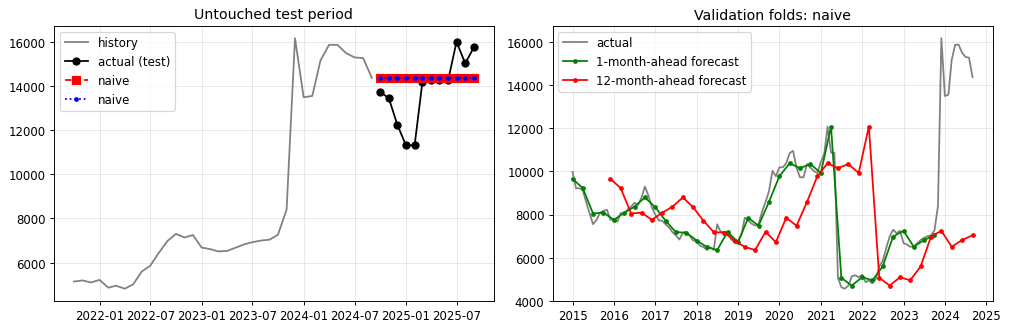

In [25]:
# Actual vs predicted: (a) test period for the selected model and the naive baseline, (b) 1-step and 12-step validation forecasts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ctx = dev_series.iloc[-36:]
axes[0].plot(ctx.index, ctx, color="grey", label="history")
axes[0].plot(test_series.index, test_series, "ko-", label="actual (test)")
axes[0].plot(test_series.index, test_predictions[SELECTED_MODEL], "r--s", label=f"{SELECTED_MODEL}")
axes[0].plot(test_series.index, test_predictions["naive"], "b:.", label="naive")
axes[0].set_title("Untouched test period"); axes[0].legend()

act, prd = validation_cache[SELECTED_MODEL]
months_h1 = [dev_series.index[o] for o in VAL_ORIGINS]
months_h12 = [dev_series.index[o + HORIZON - 1] for o in VAL_ORIGINS]
axes[1].plot(dev_series.index[MIN_TRAIN_MONTHS:], dev_series.iloc[MIN_TRAIN_MONTHS:], color="grey", label="actual")
axes[1].plot(months_h1, prd[:, 0], "g.-", label="1-month-ahead forecast")
axes[1].plot(months_h12, prd[:, -1], "r.-", label="12-month-ahead forecast")
axes[1].set_title(f"Validation folds: {SELECTED_MODEL}"); axes[1].legend()
plt.tight_layout(); plt.show()

In [26]:
# Residual diagnostics on validation (log scale errors: log(actual) - log(predicted)).
act, prd = validation_cache[SELECTED_MODEL]
log_err = np.log(act) - np.log(prd)
horizon_table = pd.DataFrame({
    "horizon": np.arange(1, HORIZON + 1),
    "MAE": np.mean(np.abs(act - prd), axis=0),
    "bias_%": np.mean(act / prd - 1, axis=0) * 100,           # >0 => the model under-forecasts on average
    "error_std_%": np.std(log_err, axis=0) * 100,
}).set_index("horizon").round(2)
display(horizon_table)

# Largest test-period misses (price shocks) for the selected model.
test_err = pd.DataFrame({"actual": test_series, "forecast": test_predictions[SELECTED_MODEL]})
test_err["error"] = test_err["actual"] - test_err["forecast"]
test_err["error_%"] = test_err["error"] / test_err["actual"] * 100
print(f"Mean signed test error (bias): {test_err['error'].mean():.1f} ({test_err['error_%'].mean():+.1f}%)")
print("Largest misses in the test period:")
display(test_err.reindex(test_err["error"].abs().sort_values(ascending=False).index).head(3).round(1))

Mean signed test error (bias): -546.0 (-5.2%)
Largest misses in the test period:


,MAE,bias_%,error_std_%
horizon,,,
1,288.33,0.65,5.06
2,443.50,0.94,7.12
3,963.67,3.90,21.74
4,1003.94,3.58,21.80
5,1080.06,4.16,22.59
6,1496.47,7.46,29.57
7,1508.44,7.25,28.97
8,1607.17,8.04,29.59
9,2066.03,11.71,35.85


,actual,forecast,error,error_%
date,,,,
2025-01-01,11313.0,14363.0,-3050.0,-27.0
2025-02-01,11313.0,14363.0,-3050.0,-27.0
2024-12-01,12250.0,14363.0,-2113.0,-17.2


## 9. Twelve-month forecast with uncertainty

1. **Refit** the selected model on **all** cleaned observations.
2. Forecast the next 12 consecutive months after the last valid observation.
3. **Prediction intervals** are *empirical*: we take the out-of-sample log-errors `log(actual) − log(forecast)` from all validation folds, divide each by √h (error spread of a trending/random-walk price grows roughly like √h), pool them, and take quantiles. Pooling ~36 folds × 12 horizons gives far more stable tail estimates than per-horizon quantiles from only ~36 overlapping folds, keeps asymmetry (no normality assumption), and makes width grow smoothly with the horizon.

We first check whether those intervals were well calibrated on the untouched test period (12 points: a coarse check).

In [27]:
def empirical_interval_factors(actual: np.ndarray, predicted: np.ndarray, coverage: float) -> Tuple[np.ndarray, np.ndarray]:
    """Return multiplicative (lower, upper) factors per horizon from validation log-errors.

    Errors from all folds and horizons are pooled after dividing by sqrt(h) (uncertainty of a trending / random-walk
    series grows roughly with the square root of the horizon). Pooling gives ~36 x 12 values per quantile instead of
    ~36 per horizon, which keeps the tail estimates stable; widths grow smoothly with h by construction.
    """
    log_err = np.log(actual) - np.log(predicted)                   # shape (folds, horizon)
    steps = np.arange(1, log_err.shape[1] + 1)
    scaled = log_err / np.sqrt(steps)                              # pooled, sqrt-time-standardised errors
    tail = (1 - coverage) / 2
    lower_q = min(np.quantile(scaled, tail), 0.0) * np.sqrt(steps)  # always straddle zero error
    upper_q = max(np.quantile(scaled, 1 - tail), 0.0) * np.sqrt(steps)
    return np.exp(lower_q), np.exp(upper_q)


# Interval calibration from validation folds, evaluated on the untouched test forecasts.
act_val, prd_val = validation_cache[SELECTED_MODEL]
cal_rows = {}
for cov in (0.80, 0.95):
    lo_f, hi_f = empirical_interval_factors(act_val, prd_val, cov)
    pt = test_predictions[SELECTED_MODEL]
    inside = (test_series.values >= pt * lo_f) & (test_series.values <= pt * hi_f)
    cal_rows[f"{int(cov*100)}%"] = {"nominal": cov, "test_coverage": inside.mean(), "mean_rel_width_%": np.mean((hi_f - lo_f)) * 100}
display(pd.DataFrame(cal_rows).T.round(3))
print("Coverage is measured on only 12 test months, so treat it as a rough check, not proof of calibration.")

Coverage is measured on only 12 test months, so treat it as a rough check, not proof of calibration.


,nominal,test_coverage,mean_rel_width_%
80%,0.80,0.75,44.315
95%,0.95,1.00,138.135


In [28]:
# Refit on ALL data and forecast the next 12 months.
final_point = forecast_with(SELECTED_MODEL, price, HORIZON, SELECTED_PARAMS)
future_index = pd.date_range(price.index[-1] + pd.DateOffset(months=1), periods=HORIZON, freq="MS", name="date")

# Intervals from validation errors (80% and 95%).
lo80, hi80 = empirical_interval_factors(act_val, prd_val, 0.80)
lo95, hi95 = empirical_interval_factors(act_val, prd_val, 0.95)
forecast_df = pd.DataFrame({
    "forecast": final_point, "lower_80": final_point * lo80, "upper_80": final_point * hi80,
    "lower_95": final_point * lo95, "upper_95": final_point * hi95,
}, index=future_index).round(1)
forecast_df["change_vs_last_obs_%"] = ((forecast_df["forecast"] / price.iloc[-1] - 1) * 100).round(2)
forecast_df["horizon"] = np.arange(1, HORIZON + 1)

print(f"Last observation: {price.index[-1]:%Y-%m} = {price.iloc[-1]:,.0f} | model: {SELECTED_MODEL} {SELECTED_PARAMS}")
display(forecast_df)

# Hard checks required by the assignment: exactly 12 consecutive months directly after the data, all finite.
assert len(forecast_df) == 12
assert (forecast_df.index == pd.date_range(price.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")).all()
assert np.isfinite(forecast_df.drop(columns="horizon").values).all()

Last observation: 2025-09 = 15,750 | model: naive {}


,forecast,lower_80,upper_80,lower_95,upper_95,change_vs_last_obs_%,horizon
date,,,,,,,
2025-10-01,15750.0,14828.6,17557.2,12055.8,20401.4,0.0,1
2025-11-01,15750.0,14462.9,18365.2,10792.2,22709.5,0.0,2
2025-12-01,15750.0,14188.4,19010.4,9913.2,24656.2,0.0,3
2026-01-01,15750.0,13961.0,19571.8,9228.1,26426.4,0.0,4
2026-02-01,15750.0,13763.8,20080.2,8663.8,28091.0,0.0,5
2026-03-01,15750.0,13587.8,20551.2,8183.3,29685.9,0.0,6
2026-04-01,15750.0,13428.0,20994.0,7765.1,31232.5,0.0,7
2026-05-01,15750.0,13280.9,21414.7,7395.1,32744.3,0.0,8
2026-06-01,15750.0,13144.3,21817.6,7063.6,34230.7,0.0,9


80% interval relative width (% of forecast): h=1: 17.3%, h=6: 44.2%, h=12: 64.5%


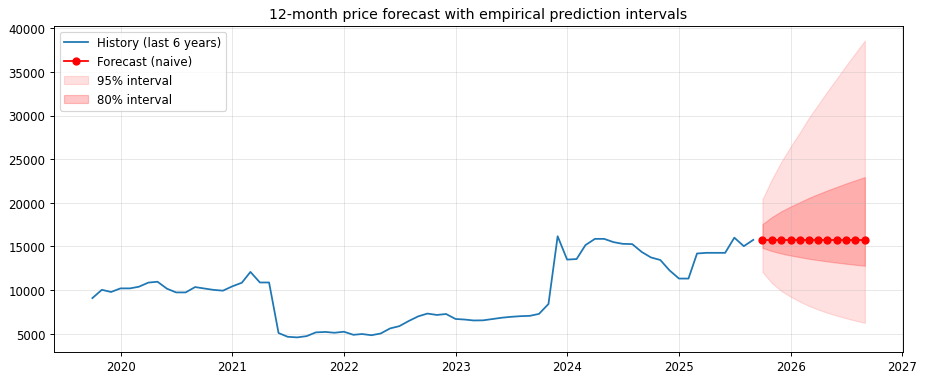

In [29]:
# Plot history + forecast with 80% / 95% bands.
fig, ax = plt.subplots(figsize=(11, 4.6))
recent = price.iloc[-72:]
ax.plot(recent.index, recent, color="#1f77b4", label="History (last 6 years)")
ax.plot(forecast_df.index, forecast_df["forecast"], "r-o", label=f"Forecast ({SELECTED_MODEL})")
ax.fill_between(forecast_df.index, forecast_df["lower_95"], forecast_df["upper_95"], color="red", alpha=0.12, label="95% interval")
ax.fill_between(forecast_df.index, forecast_df["lower_80"], forecast_df["upper_80"], color="red", alpha=0.22, label="80% interval")
ax.set_title("12-month price forecast with empirical prediction intervals"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(OUT_DIR / "forecast_plot.png", dpi=120); plt.show()

# Uncertainty grows with horizon: show the relative width of the 80% interval at h=1, 6, 12.
width = (forecast_df["upper_80"] - forecast_df["lower_80"]) / forecast_df["forecast"] * 100
print("80% interval relative width (% of forecast): " + ", ".join(f"h={h}: {width.iloc[h-1]:.1f}%" for h in (1, 6, 12)))

In [30]:
# Persist deliverables: forecast CSV and a lightweight, dependency-safe model artifact.
forecast_path = OUT_DIR / "price_forecast_next_12_months.csv"
forecast_df.to_csv(forecast_path, index_label="date")

# The artifact stores the model name, tuned parameters, the cleaned history and interval factors.
# ML models are re-fitted from this history on load (seconds, deterministic via fixed seed), which avoids
# pickling scikit-learn objects across library versions.
artifact = {
    "artifact_version": "1.0",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model_name": SELECTED_MODEL,
    "params": SELECTED_PARAMS,
    "horizon": HORIZON,
    "history_dates": [d.strftime("%Y-%m-%d") for d in price.index],
    "history_prices": [float(v) for v in price.values],
    "interval_factors": {"lower_80": lo80.tolist(), "upper_80": hi80.tolist(), "lower_95": lo95.tolist(), "upper_95": hi95.tolist()},
    "validation_metrics": best_by_model[SELECTED_MODEL]["metrics"],
    "test_metrics": sel_test,
    "library_versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
}
artifact_path = OUT_DIR / "price_model_artifact.joblib"
joblib.dump(artifact, artifact_path)
print("Saved:", forecast_path, "|", artifact_path, f"({artifact_path.stat().st_size/1024:.1f} KB)")


def forecast_from_artifact(path: Path, horizon: Optional[int] = None) -> pd.DataFrame:
    """Reload the artifact and produce the forecast table; this is the function the web services call."""
    art = joblib.load(path)
    history = pd.Series(art["history_prices"], index=pd.to_datetime(art["history_dates"]), name="price")
    h = int(horizon or art["horizon"])
    point = forecast_with(art["model_name"], history, h, art["params"])
    idx = pd.date_range(history.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS", name="date")
    f = art["interval_factors"]
    return pd.DataFrame({"forecast": point, "lower_80": point * np.array(f["lower_80"])[:h], "upper_80": point * np.array(f["upper_80"])[:h],
                         "lower_95": point * np.array(f["lower_95"])[:h], "upper_95": point * np.array(f["upper_95"])[:h]}, index=idx)


# Round-trip check: reloaded artifact must reproduce the notebook forecast.
reloaded = forecast_from_artifact(artifact_path)
print("Reload reproduces forecast:", bool(np.allclose(reloaded["forecast"].round(1), forecast_df["forecast"])))

Saved: outputs/price_forecast_next_12_months.csv | outputs/price_model_artifact.joblib (6.3 KB)
Reload reproduces forecast: True


# Answers to the Internship Assignment Questions

Questions 1–4 are answered by code cells that print their conclusions from the **executed results above** (so the numbers cannot drift from the analysis). Questions 5–9 are design answers; their code samples are representative and are **not executed in this notebook** (see Section 15 for exactly what was and was not tested).

## Question 1 — Data cleaning (missing values, outliers, anomalies)

In [31]:
print("QUESTION 1 - WHAT WAS DONE AND WHAT WAS FOUND")
print("=" * 70)
print(f"Rows read: {clean_report['rows_raw']} | clean monthly series: {clean_report['rows_clean']} months "
      f"({price.index[0]:%Y-%m} to {price.index[-1]:%Y-%m}).")
print(f"Invalid dates: {clean_report['invalid_dates']} | malformed/missing prices: {clean_report['malformed_or_missing_prices']} | "
      f"non-positive prices: {clean_report['non_positive_prices']} | duplicate months: {clean_report['duplicate_months']}.")
print(f"Missing months in the regular monthly index: {clean_report['missing_months_before_fill']} -> imputed {clean_report['imputed_months']} "
      f"(policy: time interpolation, gaps <= 3 months only); unresolved: {clean_report['unresolved_missing_months']}.")
print(f"Outlier screening (robust z > 3.5 on log-returns): {kept_flagged} months flagged; all kept as genuine market moves "
      f"because they are positive, plausible, and not demonstrably data errors. Values removed or winsorised: {removed_values}.")
if kept_flagged:
    names = ", ".join(f"{d:%Y-%m} ({r.price:,.0f})" for d, r in flagged.iterrows())
    print(f"  Flagged months: {names}")
print(f"Consecutive identical prices (possible carried-forward values): {len(repeats)} month(s): "
      f"{', '.join(f'{d:%Y-%m}' for d in repeats.index)}. They were kept (a flat month is plausible) but are flagged for source verification.")
print("Effect on forecasting: keeping genuine shocks widens the empirical prediction intervals (honest uncertainty); "
      "removing them would have made forecasts look more precise than the data supports.")

QUESTION 1 - WHAT WAS DONE AND WHAT WAS FOUND
Rows read: 249 | clean monthly series: 249 months (2005-01 to 2025-09).
Invalid dates: 0 | malformed/missing prices: 0 | non-positive prices: 0 | duplicate months: 0.
Missing months in the regular monthly index: 0 -> imputed 0 (policy: time interpolation, gaps <= 3 months only); unresolved: 0.
Outlier screening (robust z > 3.5 on log-returns): 14 months flagged; all kept as genuine market moves because they are positive, plausible, and not demonstrably data errors. Values removed or winsorised: 0.
  Flagged months: 2005-06 (5,058), 2005-12 (3,813), 2006-02 (4,755), 2006-04 (3,500), 2006-05 (6,000), 2006-06 (4,964), 2009-08 (6,964), 2013-10 (7,744), 2013-11 (11,016), 2018-07 (7,550), 2021-06 (5,070), 2023-12 (16,163), 2024-01 (13,488), 2025-03 (14,188)
Consecutive identical prices (possible carried-forward values): 9 month(s): 2018-09, 2018-10, 2020-02, 2020-08, 2021-05, 2024-05, 2025-02, 2025-05, 2025-06. They were kept (a flat month is pla

## Question 2 — Model description and why it was selected

In [32]:
MODEL_DESCRIPTIONS = {
    "naive": "Forecast = last observed price. Assumes a random walk with no drift.",
    "seasonal_naive": "Forecast = price of the same month one year earlier.",
    "moving_average": "Forecast = mean of the last `window` months.",
    "drift": "Random walk with drift on log prices: last log price + average monthly log growth over a lookback window.",
    "ses": "Simple exponential smoothing of log price (adaptive level, no trend).",
    "damped_holt": "Exponential smoothing with a level and a damped trend on log prices: l_t = a*y_t + (1-a)(l_{t-1}+phi*b_{t-1}); "
                   "b_t = beta*(l_t-l_{t-1}) + (1-beta)*phi*b_{t-1}; forecast_h = l + (phi+...+phi^h)*b. phi<1 makes growth fade with horizon.",
    "ridge_lags": "Ridge regression predicting the next monthly log-return from lagged returns, momentum, mean-reversion gap, volatility and "
                  "month-of-year; recursive multi-step forecasting; features standardised inside a pipeline.",
    "hist_gbm": "Gradient-boosted shallow trees predicting the next monthly log-return from the same features; recursive multi-step forecasting.",
}
print("QUESTION 2 - SELECTED MODEL")
print("=" * 70)
print(f"Selected model : {SELECTED_MODEL}")
print(f"Parameters     : {SELECTED_PARAMS}")
print(f"Description    : {MODEL_DESCRIPTIONS[SELECTED_MODEL]}")
if SELECTED_MODEL in ("ses", "damped_holt"):
    state = fit_smoothing(price, damped=(SELECTED_MODEL == "damped_holt"))
    print(f"Estimated on all data: alpha={state['alpha']:.3f}, beta={state['beta']:.3f}, phi={state['phi']:.3f}, "
          f"current monthly trend={np.expm1(state['trend']) * 100:+.2f}% per month")
if SELECTED_MODEL in ("ridge_lags", "hist_gbm"):
    print("Features       :", ", ".join(FEATURE_NAMES))
print("Target / scale : log price (smoothing) or next-month log-return (ML); forecasts are back-transformed to price.")
print()
ranking = comparison[["MAE", "RMSE", "WAPE_%", "seconds"]].copy()
ranking["test_MAE"] = test_table["MAE"].reindex(ranking.index)
print("Alternatives considered (validation rolling-origin metrics; test MAE shown for transparency only):")
display(ranking)
print(f"Why this model: lowest validation MAE ({comparison.loc[SELECTED_MODEL, 'MAE']:.1f}) among {len(comparison)} candidates; "
      f"practically tied models: {tied}; best non-naive challenger '{CHALLENGER}' ({comparison.loc[CHALLENGER, 'MAE']:.1f}) beats naive in "
      f"{win_rate:.0%} of validation folds. With no tested model reliably beating the benchmark, the simplest tied model is the defensible choice "
      "(no fitting, no parameters, trivially deployable).")
if SELECTED_MODEL == "naive":
    print("Honest reading: over 12-month horizons this price series behaves like a random walk - the best point forecast is the latest price, "
          "and the real value of the model is the calibrated uncertainty band, not a predicted trend.")
print(f"Seasonality evidence: seasonal strength = {seasonal_strength:.3f}; seasonal-naive validation MAE = {comparison.loc['seasonal_naive', 'MAE']:.1f} "
      f"vs naive {comparison.loc['naive', 'MAE']:.1f}.")
print("Assumptions: the latest price level is the best guide and volatility stays similar to history; no structural break or external shock; "
      "no exogenous variables were supplied, so none are used.")

QUESTION 2 - SELECTED MODEL
Selected model : naive
Parameters     : {}
Description    : Forecast = last observed price. Assumes a random walk with no drift.
Target / scale : log price (smoothing) or next-month log-return (ML); forecasts are back-transformed to price.

Alternatives considered (validation rolling-origin metrics; test MAE shown for transparency only):
Why this model: lowest validation MAE (1422.6) among 8 candidates; practically tied models: ['naive', 'ses', 'damped_holt']; best non-naive challenger 'ses' (1426.1) beats naive in 53% of validation folds. With no tested model reliably beating the benchmark, the simplest tied model is the defensible choice (no fitting, no parameters, trivially deployable).
Honest reading: over 12-month horizons this price series behaves like a random walk - the best point forecast is the latest price, and the real value of the model is the calibrated uncertainty band, not a predicted trend.
Seasonality evidence: seasonal strength = 0.045; se

,MAE,RMSE,WAPE_%,seconds,test_MAE
naive,1422.56,2514.38,17.62,0.01,1160.33
ses,1426.13,2509.22,17.67,0.15,1164.70
damped_holt,1426.72,2509.66,17.67,0.83,1167.98
drift,1450.90,2555.14,17.97,0.01,1217.93
ridge_lags,1560.77,2619.65,19.33,0.82,1254.60
hist_gbm,1602.86,2742.15,19.86,2.47,1139.68
moving_average,1707.02,2667.10,21.15,0.01,1711.78
seasonal_naive,2100.82,2990.90,26.02,0.01,2296.42


## Question 3 — Model performance

In [33]:
print("QUESTION 3 - PERFORMANCE OF THE SELECTED MODEL")
print("=" * 70)
v, t = best_by_model[SELECTED_MODEL]["metrics"], sel_test
nv_v = best_by_model["naive"]["metrics"]
summary = pd.DataFrame({
    "selected_validation": v, "naive_validation": nv_v, "selected_test": t, "naive_test": nv_test
}).round(2)
display(summary)
print(f"Validation: {len(VAL_ORIGINS)} expanding-window origins x {HORIZON} months, all before {test_series.index[0]:%Y-%m}.")
print(f"Test: {len(test_series)} untouched months. MAE {t['MAE']:.0f} ({t['WAPE_%']:.1f}% of the average actual price) "
      f"vs naive {nv_test['MAE']:.0f}.")
print(f"Error grows with horizon: MAE h=1 {horizon_table.loc[1, 'MAE']:.0f} -> h=12 {horizon_table.loc[12, 'MAE']:.0f}.")
print(f"Bias: mean signed test error {test_err['error'].mean():+.0f} ({test_err['error_%'].mean():+.1f}%). "
      f"Validation bias at h=12: {horizon_table.loc[12, 'bias_%']:+.1f}% (positive = model under-forecasts).")
print("Limitations: one 12-month test window is a small sample; shocks (see flagged months) are not predictable from price history alone; "
      "validation scores are mildly optimistic because the same folds tune and select; intervals were calibrated on validation folds that overlap.")

QUESTION 3 - PERFORMANCE OF THE SELECTED MODEL
Validation: 36 expanding-window origins x 12 months, all before 2024-10.
Test: 12 untouched months. MAE 1160 (8.4% of the average actual price) vs naive 1160.
Error grows with horizon: MAE h=1 288 -> h=12 2533.
Bias: mean signed test error -546 (-5.2%). Validation bias at h=12: +15.1% (positive = model under-forecasts).
Limitations: one 12-month test window is a small sample; shocks (see flagged months) are not predictable from price history alone; validation scores are mildly optimistic because the same folds tune and select; intervals were calibrated on validation folds that overlap.


,selected_validation,naive_validation,selected_test,naive_test
MAE,1422.56,1422.56,1160.33,1160.33
RMSE,2514.38,2514.38,1565.74,1565.74
MAPE_%,17.83,17.83,9.12,9.12
WAPE_%,17.62,17.62,8.40,8.40
sMAPE_%,16.75,16.75,8.53,8.53


## Question 4 — Business actions in response to the predicted price movements

The recommendation is **conditional on the measured forecast**: the code classifies the signal using the 80 % interval (a price move is only treated as a "signal" if the whole interval is on one side of today's price), and then prints the playbook that matches. *Assumption:* the user of the forecast is a business that both buys and sells this commodity; the actions are written for both sides.

In [34]:
last_price = float(price.iloc[-1])
signal = {}
# Classify direction at 3, 6 and 12 months: UP / DOWN only if the 80% band excludes today's price.
for h in (3, 6, 12):
    row = forecast_df.iloc[h - 1]
    signal[h] = "UP" if row["lower_80"] > last_price else ("DOWN" if row["upper_80"] < last_price else "UNCERTAIN")
central_12 = forecast_df.iloc[-1]["change_vs_last_obs_%"]
cheap_month, dear_month = forecast_df["forecast"].idxmin(), forecast_df["forecast"].idxmax()
spread_pct = (forecast_df["forecast"].max() / forecast_df["forecast"].min() - 1) * 100
band12 = (forecast_df.iloc[-1]["upper_80"] - forecast_df.iloc[-1]["lower_80"]) / forecast_df.iloc[-1]["forecast"] * 100

print("QUESTION 4 - FORECAST-DRIVEN ACTIONS")
print("=" * 70)
print(f"Last observed price ({price.index[-1]:%Y-%m}): {last_price:,.0f}")
print(f"Central forecast: {forecast_df.iloc[0]['forecast']:,.0f} next month -> {forecast_df.iloc[-1]['forecast']:,.0f} in 12 months "
      f"({central_12:+.1f}% vs last observation)")
print(f"Signal strength (80% band vs today's price): 3m={signal[3]}, 6m={signal[6]}, 12m={signal[12]}")
print(f"Lowest forecast month {cheap_month:%b %Y} ({forecast_df['forecast'].min():,.0f}); highest {dear_month:%b %Y} "
      f"({forecast_df['forecast'].max():,.0f}); spread {spread_pct:.1f}% vs 12-month 80%-band width {band12:.0f}% of forecast.")
within_noise = spread_pct < band12
print("Timing within the year:", "differences between months are SMALLER than forecast uncertainty -> do not trade on 'best month' alone."
      if within_noise else "month-to-month differences exceed uncertainty -> timing is worth acting on, still with limits.")

PLAYBOOK = {
    "UP": {
        "Procurement": "Forward-buy / contract a larger share (e.g. 50-70%) of 6-12 month needs now; use staged tranches, not one purchase.",
        "Inventory": "Raise safety stock toward the upper end of storage and spoilage limits; avoid over-stocking perishable items.",
        "Supplier contracts": "Negotiate fixed or capped-price contracts with volume commitments; add price-review clauses.",
        "Sales / pricing": "Adjust selling prices or add pass-through clauses before costs rise; shorten quote validity.",
        "Working capital": "Reserve cash for earlier, larger purchases; arrange credit lines in advance.",
        "Risk": "Set a stop-review if actual prices fall below the 80% lower band (you may have locked in above-market prices).",
    },
    "DOWN": {
        "Procurement": "Defer discretionary purchases; buy for immediate needs and use short-term contracts.",
        "Inventory": "Run inventory lean to avoid holding stock whose value is expected to fall.",
        "Supplier contracts": "Avoid long fixed-price commitments; negotiate index-linked or lower-price renewals.",
        "Sales / pricing": "Sell or forward-contract existing stock early; hold flexible pricing for new volumes.",
        "Working capital": "Release cash from stock; keep dry powder to buy lower later.",
        "Risk": "Set a stop-review if actual prices rise above the 80% upper band (you may be under-hedged).",
    },
    "UNCERTAIN": {
        "Procurement": "Ladder purchases evenly (e.g. equal monthly tranches) and keep 20-30% of needs on the spot market; the forecast does not justify a one-sided bet.",
        "Inventory": "Hold normal safety stock sized from demand and lead time, not from price expectations.",
        "Supplier contracts": "Prefer flexible volumes and index-linked pricing; limit fixed-price share until a clearer signal appears.",
        "Sales / pricing": "Keep margin buffers equal to the interval width; review prices monthly against actuals.",
        "Working capital": "Maintain liquidity buffers proportional to the 80% band; avoid large price-dependent commitments.",
        "Risk": "Scenario plan for the lower and upper bands; set monthly review triggers when actuals leave the 80% band.",
    },
}
# Choose the posture from the medium-term signal (6m) and confirm with the 12m signal; disagreement -> uncertain.
posture = signal[6] if signal[6] == signal[12] else "UNCERTAIN"
print(f"\nRecommended posture: {posture}  (6m signal {signal[6]}, 12m signal {signal[12]})")
for area, action in PLAYBOOK[posture].items():
    print(f"  - {area}: {action}")
print("\nIf actual prices leave the 80% band for 2 consecutive months, re-run the forecast and re-classify the posture.")

QUESTION 4 - FORECAST-DRIVEN ACTIONS
Last observed price (2025-09): 15,750
Central forecast: 15,750 next month -> 15,750 in 12 months (+0.0% vs last observation)
Signal strength (80% band vs today's price): 3m=UNCERTAIN, 6m=UNCERTAIN, 12m=UNCERTAIN
Lowest forecast month Oct 2025 (15,750); highest Oct 2025 (15,750); spread 0.0% vs 12-month 80%-band width 65% of forecast.
Timing within the year: differences between months are SMALLER than forecast uncertainty -> do not trade on 'best month' alone.

Recommended posture: UNCERTAIN  (6m signal UNCERTAIN, 12m signal UNCERTAIN)
  - Procurement: Ladder purchases evenly (e.g. equal monthly tranches) and keep 20-30% of needs on the spot market; the forecast does not justify a one-sided bet.
  - Inventory: Hold normal safety stock sized from demand and lead time, not from price expectations.
  - Supplier contracts: Prefer flexible volumes and index-linked pricing; limit fixed-price share until a clearer signal appears.
  - Sales / pricing: Keep m

## Question 5 — How to determine whether the actions are effective

**Principle: separate *forecast accuracy* from *business impact*.** MAE/WAPE say whether the forecast was good; they do not say whether acting on it made money. A good forecast with a bad action policy, or a bad forecast that happened to profit, are both possible. So we evaluate the **decision policy** as a separate experiment.

### 5.1 Define the policy and the baseline *before* acting
* Write down the rule (e.g. "buy 60 % of H2 volume forward when the 6- and 12-month signals are UP").
* Freeze the **pre-implementation baseline**: at least 12–24 months of previous purchase cost, price variance, stock-outs and holding cost, plus the *status-quo policy* (e.g. buy monthly on the spot market).
* Pre-register the evaluation window (e.g. 6–12 months), the KPIs, and decision thresholds, so success cannot be redefined afterwards.

### 5.2 KPIs
| KPI | Definition | Success rule (example – set with finance) |
|---|---|---|
| Purchase-price variance (PPV) | (actual average purchase price − benchmark price) × volume | lower than control by a margin that exceeds its noise band |
| Cost avoided vs. spot | Σ(spot price in the month − price paid) × volume | positive and > transaction costs |
| Inventory holding cost | average stock × (storage + capital + spoilage rate) | not up by more than the savings it bought |
| Stock-out frequency | months or order-lines with unmet demand ÷ total | not worse than baseline |
| Gross margin | (revenue − COGS) ÷ revenue | improves or is protected in falling-price phases |
| Forecast-vs-actual price error | MAE / WAPE of the live forecast | within the validation band; feeds Question 9 |
| ROI | (benefit − cost of programme) ÷ cost of programme | > hurdle rate over the window |

### 5.3 Attribution (the causal question)
1. **Control group / staggered roll-out:** apply the policy to some products, branches or suppliers (treatment) and keep others on the old policy (control). Use *difference-in-differences*: (treatment after − treatment before) − (control after − control before). This removes market-wide price moves, seasonality and inflation.
2. **Matched comparison** when randomisation is impossible: match on category, volume, supplier, region and past price behaviour.
3. **Counterfactual replay:** recompute what the old policy would have paid using actual prices (a transparent "what-if" benchmark).
4. **Confounders to track:** seasonality, demand shocks, weather, policy changes, supplier disruptions, exchange rates, plus your own volume changes. Report results *with confidence intervals* (bootstrap by month) rather than a single number.
5. **Decision thresholds:** scale up if the savings' lower confidence bound is positive after costs and no KPI (stock-outs, margin) deteriorates; modify if the benefit is positive but not significant; stop if the policy loses against control for two consecutive review cycles.

### 5.4 Cadence
Monthly dashboard (cost vs. benchmark, stock-outs); quarterly review of the policy; end-of-window analysis with the pre-registered thresholds. Failures are classified as *forecast error* (model problem, goes to retraining), *execution error* (policy not followed) or *market shock* (outside the 95 % band).

## Question 6 — Deploying the model to production with Django

> **Status:** representative design and code. **Not executed** in this notebook (Django is not installed in this environment).

### 6.1 Architecture
```
Browser / Mobile ──HTTPS──▶ Nginx ──▶ Gunicorn (Django + DRF) ──▶ PostgreSQL
                                          │                         ▲
                                          ├──▶ Redis (cache, Celery broker)
                                          └──▶ Celery worker / beat ─┘  (monthly forecast, backtest, retrain)
Model artifact (joblib) in versioned storage (S3 / volume) loaded by the worker and web process
```

### 6.2 Project structure
```
price_platform/
├── manage.py
├── config/ (settings/base.py, prod.py, urls.py, celery.py)
├── forecasting/
│   ├── core.py            # SAME functions as this notebook (clean_monthly_series, forecast_with, forecast_from_artifact)
│   ├── models.py          # PriceObservation, ModelVersion, ForecastRun, ForecastPoint
│   ├── serializers.py     # DRF input/output validation
│   ├── views.py           # REST endpoints
│   ├── tasks.py           # Celery jobs
│   ├── services.py        # loads artifact, caches, calls core
│   └── tests/
├── requirements.txt
└── Dockerfile / docker-compose.yml
```

### 6.3 Database and prediction history
```python
# forecasting/models.py
from django.db import models

class PriceObservation(models.Model):
    month = models.DateField(unique=True)               # always the 1st of the month
    avg_price = models.DecimalField(max_digits=12, decimal_places=2)
    source = models.CharField(max_length=50, default="manual")
    created_at = models.DateTimeField(auto_now_add=True)

class ModelVersion(models.Model):
    name = models.CharField(max_length=50)              # e.g. "damped_holt"
    version = models.CharField(max_length=20, unique=True)
    artifact_path = models.CharField(max_length=255)
    validation_mae = models.FloatField()
    test_mae = models.FloatField()
    status = models.CharField(max_length=12, choices=[("candidate","candidate"),("active","active"),("retired","retired")])
    trained_at = models.DateTimeField()

class ForecastRun(models.Model):
    model_version = models.ForeignKey(ModelVersion, on_delete=models.PROTECT)
    created_at = models.DateTimeField(auto_now_add=True)
    requested_by = models.ForeignKey("auth.User", null=True, on_delete=models.SET_NULL)
    horizon = models.PositiveSmallIntegerField()

class ForecastPoint(models.Model):
    run = models.ForeignKey(ForecastRun, related_name="points", on_delete=models.CASCADE)
    month = models.DateField()
    forecast = models.FloatField(); lower_80 = models.FloatField(); upper_80 = models.FloatField()
    lower_95 = models.FloatField(); upper_95 = models.FloatField()
    actual = models.FloatField(null=True, blank=True)    # filled when the real price arrives (Question 9)
    class Meta:
        unique_together = ("run", "month")
```

### 6.4 Model loading, validation, endpoints
```python
# forecasting/services.py  — load once per process, never per request
from functools import lru_cache
from pathlib import Path
from django.conf import settings
from .core import forecast_from_artifact

@lru_cache(maxsize=2)
def _artifact_path(version: str) -> Path:
    return Path(settings.MODEL_DIR) / f"price_model_{version}.joblib"

def run_forecast(version: str, horizon: int):
    return forecast_from_artifact(_artifact_path(version), horizon)   # DataFrame with 5 columns
```
```python
# forecasting/serializers.py — strict input validation
from rest_framework import serializers

class ForecastRequestSerializer(serializers.Serializer):
    horizon = serializers.IntegerField(min_value=1, max_value=24, default=12)

# forecasting/views.py
from rest_framework.views import APIView
from rest_framework.response import Response
from rest_framework.permissions import IsAuthenticated
from rest_framework.throttling import UserRateThrottle
import logging
logger = logging.getLogger(__name__)

class ForecastView(APIView):
    permission_classes = [IsAuthenticated]          # JWT (SimpleJWT) or session auth
    throttle_classes = [UserRateThrottle]

    def post(self, request):
        s = ForecastRequestSerializer(data=request.data); s.is_valid(raise_exception=True)
        version = ModelVersion.objects.get(status="active")
        try:
            df = run_forecast(version.version, s.validated_data["horizon"])
        except ValueError as exc:                   # e.g. insufficient history -> client-visible 422
            return Response({"detail": str(exc)}, status=422)
        except Exception:
            logger.exception("forecast failed")     # stack trace to logs, generic message to client
            return Response({"detail": "Forecast temporarily unavailable"}, status=503)
        run = ForecastRun.objects.create(model_version=version, requested_by=request.user, horizon=len(df))
        ForecastPoint.objects.bulk_create([ForecastPoint(run=run, month=i.date(), **r) for i, r in df.iterrows()])
        return Response({"model": version.name, "version": version.version, "forecast": df.reset_index().assign(date=lambda d: d.date.dt.strftime("%Y-%m-%d")).to_dict("records")})
```
* **Permissions:** `IsAuthenticated` for reads; an `IsAnalyst` group permission for `/admin/retrain`; Django admin only for staff.
* **Scheduled forecasting:** a Celery beat task on the 3rd of each month: ingest the latest price → validate (`clean_monthly_series`) → forecast → store `ForecastRun` → alert on failure.
```python
# forecasting/tasks.py
from celery import shared_task
@shared_task(bind=True, max_retries=3, default_retry_delay=300)
def monthly_forecast(self):
    ...  # fetch new observation, validate, run_forecast(active_version, 12), persist, notify
```
* **Testing:** `pytest-django` tests for serializers (bad horizon → 400), auth (401/403), forecast length 12, 422 on short history; CI runs them on each push.
* **Security / deployment:** `DEBUG=False`, secrets from environment variables, `ALLOWED_HOSTS`, HTTPS + HSTS, CORS allow-list for the Next.js origin, Gunicorn behind Nginx, containerised with a health endpoint `/healthz`, database migrations in the release step, artifact files outside the web root, structured JSON logging (request id, model version, latency).

## Question 7 — Integrating the model with Django and FastAPI for real-time predictions

> **Status:** representative design and code. **Not executed** here (FastAPI/Pydantic are not installed in this environment).

### 7.1 Who does what
| Concern | Django (core application) | FastAPI (prediction service) |
|---|---|---|
| Users, roles, billing, admin, DB of record, UI, history | **yes** | no |
| Low-latency inference, schema-validated JSON, auto OpenAPI docs | calls it | **yes** |
| Model artifact | *none* (no duplicate implementation) | loads the artifact + shared `core.py` |

Use **Django alone** if traffic is small (≈ a few requests/second): inference on this model takes milliseconds, and an extra service adds operational cost. Add **FastAPI** when you need independent scaling, a stricter typed contract, different release cadence for the ML team, or to expose the model to other internal systems. The shared `forecasting_core.py` package (the functions from this notebook) is installed in both, so the logic is never duplicated.

### 7.2 FastAPI service
```python
# prediction_service/app/main.py
import os, time, logging
from contextlib import asynccontextmanager
from datetime import datetime, timezone
from typing import List, Literal
from fastapi import FastAPI, Depends, Header, HTTPException, status
from pydantic import BaseModel, Field
import joblib
from forecasting_core import forecast_from_artifact

log = logging.getLogger("prediction_service")
state = {}

@asynccontextmanager
async def lifespan(app: FastAPI):
    state["path"] = os.environ["MODEL_ARTIFACT_PATH"]          # loaded once at startup
    state["artifact"] = joblib.load(state["path"])
    yield

app = FastAPI(title="Price Forecast API", version="1.0.0", lifespan=lifespan)

class ForecastRequest(BaseModel):
    horizon: int = Field(12, ge=1, le=24, description="Months to forecast")

class ForecastPoint(BaseModel):
    date: str; forecast: float
    lower_80: float; upper_80: float; lower_95: float; upper_95: float

class ForecastResponse(BaseModel):
    model: str; model_created_utc: str; generated_at: str
    horizon: int; points: List[ForecastPoint]

def require_service_token(authorization: str = Header(...)):    # Django sends a service-to-service token
    if authorization != f"Bearer {os.environ['SERVICE_TOKEN']}":
        raise HTTPException(status.HTTP_401_UNAUTHORIZED, "invalid token")

@app.get("/health")                                              # liveness/readiness probe
def health():
    return {"status": "ok", "model": state["artifact"]["model_name"]}

@app.post("/v1/forecast", response_model=ForecastResponse, dependencies=[Depends(require_service_token)])
def forecast(req: ForecastRequest):
    t0 = time.perf_counter()
    try:
        df = forecast_from_artifact(state["path"], req.horizon)
    except ValueError as exc:
        raise HTTPException(422, str(exc))
    log.info("forecast ok horizon=%s latency_ms=%.1f", req.horizon, (time.perf_counter() - t0) * 1000)
    pts = [ForecastPoint(date=i.strftime("%Y-%m-%d"), **r) for i, r in df.iterrows()]
    return ForecastResponse(model=state["artifact"]["model_name"], model_created_utc=state["artifact"]["created_utc"],
                            generated_at=datetime.now(timezone.utc).isoformat(), horizon=req.horizon, points=pts)
```
Run: `uvicorn app.main:app --workers 2`. Interactive docs are served automatically at `/docs` (Swagger) and `/redoc`.

### 7.3 Django → FastAPI call (timeouts, retries, caching)
```python
# forecasting/clients.py
import httpx, os
from django.core.cache import cache
from tenacity import retry, stop_after_attempt, wait_exponential, retry_if_exception_type

BASE, TOKEN = os.environ["PREDICTION_URL"], os.environ["SERVICE_TOKEN"]

@retry(stop=stop_after_attempt(3), wait=wait_exponential(min=0.2, max=2), retry=retry_if_exception_type(httpx.TransportError))
def _call(horizon: int) -> dict:
    r = httpx.post(f"{BASE}/v1/forecast", json={"horizon": horizon}, headers={"Authorization": f"Bearer {TOKEN}"},
                   timeout=httpx.Timeout(connect=1.0, read=3.0, write=1.0, pool=1.0))
    r.raise_for_status()
    return r.json()

def get_forecast(horizon: int, model_key: str) -> dict:
    key = f"forecast:{model_key}:{horizon}"
    data = cache.get(key)                       # forecasts change monthly -> cache for hours, key includes model version
    if data is None:
        data = _call(horizon); cache.set(key, data, 6 * 3600)
    return data
```
* **Versioning:** `/v1/…` path; breaking changes ship as `/v2/…` while `/v1` stays until clients migrate.
* **Failure behaviour:** on timeout/5xx Django serves the **last stored `ForecastRun`** with a `stale=true` flag instead of failing; a circuit breaker (e.g. stop calling for 30 s after N failures) protects the service.
* **Internal communication:** private network only (no public FastAPI port), mutual service token or mTLS, request-id header for tracing.

## Question 8 — Consuming the Django / FastAPI APIs from Next.js and React Native

> **Status:** representative TypeScript. **Not executed** here. Rule: **no secret ever appears in browser or app bundles.** Only *public* values (API base URL) are exposed; service tokens and database credentials stay on the server.

### 8.1 Next.js (web)
```bash
# .env.local  (never commit)
API_BASE_URL=https://api.example.com        # server-only (no NEXT_PUBLIC_ prefix)
```
```ts
// app/api/forecast/route.ts  — Next.js Route Handler acts as a BFF (backend-for-frontend)
import { NextRequest, NextResponse } from "next/server";
import { cookies } from "next/headers";
import { z } from "zod";

const Body = z.object({ horizon: z.number().int().min(1).max(24).default(12) });

export async function POST(req: NextRequest) {
  const parsed = Body.safeParse(await req.json());
  if (!parsed.success) return NextResponse.json({ error: parsed.error.flatten() }, { status: 400 });
  const token = (await cookies()).get("access_token")?.value;       // httpOnly cookie set at login
  if (!token) return NextResponse.json({ error: "unauthenticated" }, { status: 401 });
  const res = await fetch(`${process.env.API_BASE_URL}/api/v1/forecast/`, {
    method: "POST",
    headers: { "Content-Type": "application/json", Authorization: `Bearer ${token}` },
    body: JSON.stringify(parsed.data),
    signal: AbortSignal.timeout(8000),
  });
  return NextResponse.json(await res.json(), { status: res.status });
}
```
```tsx
// components/ForecastPanel.tsx
"use client";
import { useState } from "react";
import { LineChart, Line, XAxis, YAxis, Tooltip, Area, ResponsiveContainer } from "recharts";

type Point = { date: string; forecast: number; lower_80: number; upper_80: number };

export default function ForecastPanel() {
  const [horizon, setHorizon] = useState(12);
  const [data, setData] = useState<Point[] | null>(null);
  const [loading, setLoading] = useState(false);
  const [error, setError] = useState<string | null>(null);

  async function load() {
    if (!Number.isInteger(horizon) || horizon < 1 || horizon > 24) { setError("Horizon must be 1-24 months"); return; }
    setLoading(true); setError(null);
    try {
      const res = await fetch("/api/forecast", { method: "POST", headers: { "Content-Type": "application/json" }, body: JSON.stringify({ horizon }) });
      if (!res.ok) throw new Error(res.status === 401 ? "Please sign in" : "Forecast unavailable, try again");
      setData((await res.json()).forecast as Point[]);
    } catch (e) { setError((e as Error).message); } finally { setLoading(false); }
  }

  return (
    <section>
      <input type="number" value={horizon} min={1} max={24} onChange={(e) => setHorizon(Number(e.target.value))} />
      <button onClick={load} disabled={loading}>{loading ? "Loading…" : "Get forecast"}</button>
      {error && <p role="alert">{error}</p>}
      {data && (<>
        <ResponsiveContainer width="100%" height={300}><LineChart data={data}>
          <XAxis dataKey="date" /><YAxis /><Tooltip />
          <Line dataKey="forecast" stroke="#d62728" /><Line dataKey="lower_80" strokeDasharray="4" dot={false} /><Line dataKey="upper_80" strokeDasharray="4" dot={false} />
        </LineChart></ResponsiveContainer>
        <table><thead><tr><th>Month</th><th>Forecast</th><th>80% range</th></tr></thead><tbody>
          {data.map(p => <tr key={p.date}><td>{p.date}</td><td>{p.forecast.toFixed(0)}</td><td>{p.lower_80.toFixed(0)}–{p.upper_80.toFixed(0)}</td></tr>)}
        </tbody></table></>)}
    </section>
  );
}
```
Because the browser talks only to the Next.js route (same origin), CORS is avoided and the Django token never reaches client JavaScript. In development, `API_BASE_URL=http://localhost:8000`; in production, the HTTPS gateway URL set in the host's environment settings.

### 8.2 React Native (Expo)
```bash
# .env  → public only; EXPO_PUBLIC_* values are visible inside the app bundle, so never put secrets here
EXPO_PUBLIC_API_URL=https://api.example.com
# dev on a physical phone: use your computer's LAN address, e.g. http://192.168.1.20:8000 (Android emulator: http://10.0.2.2:8000)
```
```tsx
// api/forecast.ts
import * as SecureStore from "expo-secure-store";          // encrypted keychain/keystore for the user's JWT
const BASE = process.env.EXPO_PUBLIC_API_URL!;

export type Point = { date: string; forecast: number; lower_80: number; upper_80: number };

export async function fetchForecast(horizon: number): Promise<Point[]> {
  if (!Number.isInteger(horizon) || horizon < 1 || horizon > 24) throw new Error("Horizon must be 1-24");
  const token = await SecureStore.getItemAsync("access_token");
  if (!token) throw new Error("Not signed in");
  const controller = new AbortController(); const timer = setTimeout(() => controller.abort(), 8000);
  try {
    const res = await fetch(`${BASE}/api/v1/forecast/`, {
      method: "POST", signal: controller.signal,
      headers: { "Content-Type": "application/json", Authorization: `Bearer ${token}` },
      body: JSON.stringify({ horizon }),
    });
    if (res.status === 401) throw new Error("Session expired");           // trigger refresh-token flow here
    if (!res.ok) throw new Error("Forecast unavailable");
    return (await res.json()).forecast;
  } finally { clearTimeout(timer); }
}
```
```tsx
// screens/ForecastScreen.tsx
import { useEffect, useState } from "react";
import { ActivityIndicator, FlatList, Text, View } from "react-native";
import { fetchForecast, Point } from "../api/forecast";

export default function ForecastScreen() {
  const [data, setData] = useState<Point[]>([]); const [loading, setLoading] = useState(true); const [error, setError] = useState<string | null>(null);
  useEffect(() => { fetchForecast(12).then(setData).catch(e => setError(e.message)).finally(() => setLoading(false)); }, []);
  if (loading) return <ActivityIndicator />;
  if (error) return <Text accessibilityRole="alert">{error}</Text>;
  return (<FlatList data={data} keyExtractor={p => p.date}
    renderItem={({ item }) => <View><Text>{item.date}: {item.forecast.toFixed(0)} ({item.lower_80.toFixed(0)}–{item.upper_80.toFixed(0)})</Text></View>} />);
}
```
For charts on mobile use `react-native-svg` with `victory-native` (or `react-native-gifted-charts`). Use HTTPS only in production, store only the user's short-lived access/refresh token in SecureStore, and obtain tokens from Django's login endpoint (never ship a service token in the app).

## Question 9 — Production monitoring, model drift and model updates

### 9.1 What to monitor
| Area | Metric | How | Alert / action |
|---|---|---|---|
| Service health | availability, p50/p95/p99 latency, error rate | Prometheus + Grafana or cloud monitoring on `/health` and request logs | p95 latency over SLO for 10 min; 5xx > 1 % → page on-call |
| Input validity | validation failures (bad date, non-positive price, duplicate month), schema errors | count per day in logs | spike vs. 7-day average → inspect source feed |
| Data freshness | days since last price observation; missing months | scheduled check on day *D* of each month | observation late > 5 days → alert; forecast is marked *stale* |
| Forecast accuracy | when month *t* actual arrives, compute APE/AE for every stored forecast of *t* at horizons 1…12 (`ForecastPoint.actual`) | monthly job joining forecasts to actuals | rules in 9.3 |
| Residuals | rolling bias (mean signed error), error autocorrelation, share of actuals outside 80 % / 95 % bands | monthly | coverage far below nominal or persistent one-sided bias → recalibrate / retrain |
| Data drift | distribution of recent log-returns and levels vs. training reference: Population Stability Index (PSI), KS test, change in volatility | monthly | PSI > 0.25 = major shift (0.10–0.25 = watch) |
| Concept drift | model error relative to naive, rolling 6-month MAE vs. validation MAE | monthly | model worse than naive for 6 months → retrain |
| Prediction distribution | forecast level and implied growth vs. history | monthly | implied 12-month growth outside historic range → review |

### 9.2 Collecting actual future prices
Prices arrive monthly through the same ingestion path as training data (API/CSV upload/scraper/manual entry) into `PriceObservation`. A Celery job (a) validates it with `clean_monthly_series`, (b) back-fills `ForecastPoint.actual` for all earlier forecast runs that predicted that month, (c) recomputes the monitoring metrics, (d) writes them to a `ModelMonitoring` table/dashboard. Forecasts are **immutable** once stored, so accuracy is always judged against what was really predicted at the time.

### 9.3 Retraining and release policy
* **Scheduled retrain:** every month (cheap: seconds) – refit on all data, re-run the rolling-origin comparison, produce a *candidate*.
* **Event-triggered retrain:** (i) rolling-6-month MAE > 1.5× validation MAE, (ii) model worse than naive over the last 6 months, (iii) three consecutive months with actuals outside the 80 % band on the same side, (iv) PSI > 0.25 on recent returns, (v) data-source or business change (new market regime).
* **Approval gate:** a candidate is promoted only if it beats the *current* model on the latest rolling-origin backtest (non-inferiority at minimum) **and** passes the test suite and sanity checks (12 consecutive months, finite values, plausible growth). Human sign-off for the first deployments.
* **Versioning & rollback:** every `ModelVersion` stores code commit, data hash/range, parameters, metrics and artifact path; the previous active version stays available, so rollback = flip `status` back (seconds).
* **Periodic backtesting:** quarterly full rolling-origin re-evaluation, including a champion/challenger comparison; run candidate in *shadow mode* (predict but not serve) before promotion.

The cell below **demonstrates** the core of these rules on the real data: it replays the untouched test months as if they were arriving live (one-step-ahead, refitting each month) and applies the alert thresholds derived from validation.

In [35]:
def population_stability_index(reference: np.ndarray, recent: np.ndarray, bins: int = 5) -> float:
    """PSI between a reference sample and a recent sample, using reference quantile bins."""
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    ref_share = np.histogram(reference, edges)[0] / len(reference)
    new_share = np.histogram(recent, edges)[0] / len(recent)
    ref_share, new_share = np.clip(ref_share, 1e-4, None), np.clip(new_share, 1e-4, None)
    return float(np.sum((new_share - ref_share) * np.log(new_share / ref_share)))


# 1) Thresholds derived from VALIDATION evidence (not arbitrary): single-month 95th-percentile APE at horizon 1.
act_v, prd_v = validation_cache[SELECTED_MODEL]
val_ape_h1 = np.abs(act_v[:, 0] - prd_v[:, 0]) / act_v[:, 0]
ape_threshold = float(np.quantile(val_ape_h1, 0.95))
print(f"Validation 1-step APE: mean {val_ape_h1.mean():.1%}, 95th percentile (alert threshold) {ape_threshold:.1%}")

# 2) Replay the test months as live data: each month forecast one step ahead using only data available before it.
replay = []
for i, month in enumerate(test_series.index):
    train_so_far = price.iloc[:dev_end + i]
    pred = forecast_with(SELECTED_MODEL, train_so_far, 1, SELECTED_PARAMS)[0]
    naive_pred = float(train_so_far.iloc[-1])
    actual = float(test_series.iloc[i])
    replay.append({"month": month, "actual": actual, "forecast": pred, "ape": abs(actual - pred) / actual,
                   "naive_ape": abs(actual - naive_pred) / actual, "signed_err": actual - pred})
monitor = pd.DataFrame(replay).set_index("month")
monitor["alert_single_month"] = monitor["ape"] > ape_threshold
monitor["rolling6_ape"] = monitor["ape"].rolling(6).mean()
monitor["rolling6_naive_ape"] = monitor["naive_ape"].rolling(6).mean()
monitor["worse_than_naive_6m"] = monitor["rolling6_ape"] > monitor["rolling6_naive_ape"]
display(monitor.round(3))

# 3) Retraining triggers evaluated on the replay.
consecutive_alerts = monitor["alert_single_month"].astype(int).rolling(3).sum().eq(3).any()
mae_ratio = monitor["ape"].iloc[-6:].mean() / val_ape_h1.mean()    # latest 6 months vs validation baseline
reference_returns = log_returns.iloc[:-24].values
recent_returns = log_returns.iloc[-24:].values
psi = population_stability_index(reference_returns, recent_returns)
print(f"Trigger (a) latest-6m error > 1.5x validation error  : ratio = {mae_ratio:.2f} -> {'RETRAIN' if mae_ratio > 1.5 else 'ok'}")
print(f"Trigger (b) worse than naive over last 6 months       : {'RETRAIN' if bool(monitor['worse_than_naive_6m'].iloc[-1]) else 'ok'}")
print(f"Trigger (c) 3 consecutive single-month alerts          : {'RETRAIN' if consecutive_alerts else 'ok'}")
print(f"Trigger (d) PSI of recent 24m returns vs reference     : {psi:.3f} -> {'RETRAIN' if psi > 0.25 else ('watch' if psi > 0.10 else 'ok')}")
print("Note: thresholds are defaults derived from validation evidence; with only 12 replayed months the alerts are indicative, not conclusive.")
print(f"Interval coverage in replay is evaluated in Section 9 (calibration table); last-6-month bias: {monitor['signed_err'].iloc[-6:].mean():+.0f}")

Validation 1-step APE: mean 3.7%, 95th percentile (alert threshold) 9.8%
Trigger (a) latest-6m error > 1.5x validation error  : ratio = 1.02 -> ok
Trigger (b) worse than naive over last 6 months       : ok
Trigger (c) 3 consecutive single-month alerts          : ok
Trigger (d) PSI of recent 24m returns vs reference     : 0.369 -> RETRAIN
Note: thresholds are defaults derived from validation evidence; with only 12 replayed months the alerts are indicative, not conclusive.
Interval coverage in replay is evaluated in Section 9 (calibration table); last-6-month bias: +260


,actual,forecast,ape,naive_ape,signed_err,alert_single_month,rolling6_ape,rolling6_naive_ape,worse_than_naive_6m
month,,,,,,,,,
2024-10-01,13738.0,14363.0,0.045,0.045,-625.0,False,NaN,NaN,False
2024-11-01,13438.0,13738.0,0.022,0.022,-300.0,False,NaN,NaN,False
2024-12-01,12250.0,13438.0,0.097,0.097,-1188.0,False,NaN,NaN,False
2025-01-01,11313.0,12250.0,0.083,0.083,-937.0,False,NaN,NaN,False
2025-02-01,11313.0,11313.0,0.000,0.000,0.0,False,NaN,NaN,False
2025-03-01,14188.0,11313.0,0.203,0.203,2875.0,True,0.075,0.075,False
2025-04-01,14263.0,14188.0,0.005,0.005,75.0,False,0.068,0.068,False
2025-05-01,14263.0,14263.0,0.000,0.000,0.0,False,0.065,0.065,False
2025-06-01,14263.0,14263.0,0.000,0.000,0.0,False,0.048,0.048,False


## 15. Testing and limitations

The cell below runs **real assertions** against the functions defined in this notebook. Each test is recorded as PASSED / FAILED. Tests that need frameworks not installed here (Django, FastAPI, Celery, JavaScript) are listed separately as **NOT EXECUTED**; they are not counted as passed.

In [36]:
TEST_RESULTS: List[Tuple[str, str, str]] = []


def run_test(name: str, fn: Callable[[], None]) -> None:
    """Run one test function; record PASSED or FAILED (with the reason) instead of stopping the notebook."""
    try:
        fn()
        TEST_RESULTS.append((name, "PASSED", ""))
    except Exception as exc:                                    # noqa: BLE001 - we want to report any failure
        TEST_RESULTS.append((name, "FAILED", f"{type(exc).__name__}: {exc}"[:140]))


def validate_forecast_request(payload: dict) -> List[str]:
    """Mirror of the Pydantic/DRF request rules: returns a list of error messages (empty = valid)."""
    errors = []
    horizon = payload.get("horizon", 12)
    if isinstance(horizon, bool) or not isinstance(horizon, int):
        errors.append("horizon must be an integer")
    elif not 1 <= horizon <= MAX_HORIZON:
        errors.append(f"horizon must be between 1 and {MAX_HORIZON}")
    if "confidence" in payload and payload["confidence"] not in (80, 95):
        errors.append("confidence must be 80 or 95")
    return errors


def validate_response_schema(resp: dict) -> None:
    """Assert the response contract used by Django, FastAPI and the frontends."""
    assert {"model", "horizon", "points"} <= set(resp), "missing top-level keys"
    assert resp["horizon"] == len(resp["points"])
    for p in resp["points"]:
        assert set(p) == {"date", "forecast", "lower_80", "upper_80", "lower_95", "upper_95"}
        assert all(isinstance(p[k], float) and np.isfinite(p[k]) for k in p if k != "date")
        assert p["lower_95"] <= p["lower_80"] <= p["forecast"] <= p["upper_80"] <= p["upper_95"], "interval ordering"


def test_invalid_dates_and_prices():
    bad = pd.DataFrame({"d": ["2020-01-01", "2020-13-45", "2020-03-01", "not a date", "2020-05-01", "2020-06-01"],
                        "p": ["100", "200", "abc", "400", "-5", "600"]})
    _, mask, rep = clean_monthly_series(bad, "d", "p")
    assert rep["invalid_dates"] == 2 and rep["non_positive_prices"] == 1 and rep["malformed_or_missing_prices"] == 1
    # Feb-May is a 4-month interior gap: the <=3-month policy fills 3 months and leaves 1 visibly unresolved.
    assert rep["missing_months_before_fill"] == 4 and rep["imputed_months"] == 3 and rep["unresolved_missing_months"] == 1


def test_missing_months_policy():
    dates = [d for d in pd.date_range("2020-01-01", periods=12, freq="MS") if d.month not in (3, 4, 5, 6, 7)]
    raw = pd.DataFrame({"d": dates, "p": np.linspace(100, 200, len(dates))})
    _, _, rep = clean_monthly_series(raw, "d", "p")
    assert rep["missing_months_before_fill"] == 5 and rep["unresolved_missing_months"] == 2   # gap > 3 months is NOT silently filled


def test_duplicate_months_aggregated():
    raw = pd.DataFrame({"d": ["2020-01-01", "2020-01-15", "2020-02-01"], "p": [100, 200, 300]})
    s, _, rep = clean_monthly_series(raw, "d", "p")
    assert rep["duplicate_months"] == 1 and s.iloc[0] == 150


def test_insufficient_history():
    for name, n in (("naive", 10), ("ridge_lags", 30)):
        try:
            forecast_with(name, price.iloc[:n], 12, {} if name == "naive" else {"alpha": 10.0}); raise AssertionError("no error raised")
        except ValueError:
            pass


def test_horizon_validation():
    for bad in (0, -1, MAX_HORIZON + 1):
        try:
            forecast_with("naive", price, bad); raise AssertionError("accepted bad horizon")
        except ValueError:
            pass
    assert len(forecast_with("naive", price, 1)) == 1 and len(forecast_with("naive", price, MAX_HORIZON)) == MAX_HORIZON


def test_request_validation():
    assert validate_forecast_request({"horizon": 12}) == []
    assert validate_forecast_request({}) == []                                  # default horizon
    assert validate_forecast_request({"horizon": "abc"}) and validate_forecast_request({"horizon": 99})
    assert validate_forecast_request({"horizon": True}) and validate_forecast_request({"horizon": 6, "confidence": 90})


def test_forecast_length_dates_finite():
    assert len(forecast_df) == 12 and np.isfinite(forecast_df[["forecast", "lower_95", "upper_95"]].values).all()
    expected = pd.date_range(price.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")
    assert (forecast_df.index == expected).all() and (np.diff(forecast_df.index.values.astype("datetime64[M]").astype(int)) == 1).all()


def test_nonfinite_guard():
    MODEL_REGISTRY["_broken"] = (lambda train, horizon: np.full(horizon, np.nan), [{}])
    try:
        forecast_with("_broken", price, 3); raise AssertionError("NaN forecast not rejected")
    except FloatingPointError:
        pass
    finally:
        MODEL_REGISTRY.pop("_broken")


def test_serialization_roundtrip():
    tmp = OUT_DIR / "_roundtrip.joblib"
    joblib.dump(artifact, tmp)
    assert np.allclose(forecast_from_artifact(tmp)["forecast"].round(1), forecast_df["forecast"]); tmp.unlink()


def test_response_schema():
    pts = [{"date": d.strftime("%Y-%m-%d"), **{k: float(r[k]) for k in ("forecast", "lower_80", "upper_80", "lower_95", "upper_95")}}
           for d, r in forecast_df.iterrows()]
    validate_response_schema({"model": SELECTED_MODEL, "horizon": len(pts), "points": pts})


def test_no_future_leakage_in_features():
    X_short, _ = build_training_matrix(price.iloc[:150])
    X_long, _ = build_training_matrix(price.iloc[:200])
    assert np.allclose(X_short, X_long[:len(X_short)]), "features for early months changed when later data was added"


def test_regression_against_baseline():
    sel_mae, naive_val_mae = best_by_model[SELECTED_MODEL]["metrics"]["MAE"], best_by_model["naive"]["metrics"]["MAE"]
    assert sel_mae <= naive_val_mae, f"selected model ({sel_mae:.1f}) is worse than naive ({naive_val_mae:.1f})"
    assert abs(artifact["validation_metrics"]["MAE"] - sel_mae) < 1e-9


for test_name, test_fn in [
    ("Invalid dates and malformed prices", test_invalid_dates_and_prices),
    ("Missing monthly observations (gap policy)", test_missing_months_policy),
    ("Duplicate records aggregated", test_duplicate_months_aggregated),
    ("Insufficient training history rejected", test_insufficient_history),
    ("Forecast horizon validation", test_horizon_validation),
    ("Missing / invalid request fields", test_request_validation),
    ("Forecast length, date continuity, finite values", test_forecast_length_dates_finite),
    ("Non-finite predictions rejected", test_nonfinite_guard),
    ("Model serialization and reload", test_serialization_roundtrip),
    ("API response schema (contract)", test_response_schema),
    ("No future leakage in features", test_no_future_leakage_in_features),
    ("Regression against baseline metrics", test_regression_against_baseline),
]:
    run_test(test_name, test_fn)

results_df = pd.DataFrame(TEST_RESULTS, columns=["test", "status", "detail"])
display(results_df)
passed = int((results_df["status"] == "PASSED").sum())
print(f"\nExecuted tests: {len(results_df)} | PASSED: {passed} | FAILED: {len(results_df) - passed}")
assert passed == len(results_df), "At least one test failed - see table above."

NOT_EXECUTED = [
    "Django: pytest-django tests for DRF serializers, authentication (401/403), 422 on short history, ForecastRun persistence",
    "FastAPI: TestClient tests for /health, /v1/forecast schema (Pydantic), invalid payload -> 422, token check",
    "Celery: scheduled monthly_forecast task and retry behaviour",
    "Next.js / React Native: Jest + React Testing Library tests for loading / error / success states",
    "Load and latency tests of the deployed service",
]
print("\nNOT EXECUTED in this notebook (code/design provided, but these tests have not been run):")
for item in NOT_EXECUTED:
    print("  -", item)


Executed tests: 12 | PASSED: 12 | FAILED: 0

NOT EXECUTED in this notebook (code/design provided, but these tests have not been run):
  - Django: pytest-django tests for DRF serializers, authentication (401/403), 422 on short history, ForecastRun persistence
  - FastAPI: TestClient tests for /health, /v1/forecast schema (Pydantic), invalid payload -> 422, token check
  - Celery: scheduled monthly_forecast task and retry behaviour
  - Next.js / React Native: Jest + React Testing Library tests for loading / error / success states
  - Load and latency tests of the deployed service


,test,status,detail
0,Invalid dates and malformed prices,PASSED,
1,Missing monthly observations (gap policy),PASSED,
2,Duplicate records aggregated,PASSED,
3,Insufficient training history rejected,PASSED,
4,Forecast horizon validation,PASSED,
5,Missing / invalid request fields,PASSED,
6,"Forecast length, date continuity, finite values",PASSED,
7,Non-finite predictions rejected,PASSED,
8,Model serialization and reload,PASSED,
9,API response schema (contract),PASSED,


### Limitations and assumptions
* **Single series, no explanatory variables.** The CSV has only a date and a price. No weather, demand, policy or exchange-rate data was supplied, so none is used and none is invented. Forecasts therefore assume historical dynamics continue.
* **Unknown commodity and units.** The data dictionary says only "average monthly price"; business recommendations are written generically.
* **Small evaluation sample.** One 12-month test window and overlapping validation folds give only a rough accuracy estimate; intervals are empirical and approximate (validation also tunes and selects, so it is mildly optimistic).
* **Shocks are not forecastable from history.** Large single-month moves (flagged in Section 3) will produce errors outside the bands.
* **Possible stale values.** Identical consecutive prices should be confirmed with the data source.
* **Seasonal models not included** as separate candidates (see Section 6 for the reason); Holt-Winters/SARIMA can be added to `MODEL_REGISTRY` if `statsmodels` is available.

## 16. Conclusion and business recommendations
The executed results above (model comparison, test metrics, forecast table and the Question 4 posture) are the authoritative conclusions. In summary: the pipeline cleans without discarding genuine shocks, compares eight candidates under rolling-origin validation, selects by out-of-sample evidence, reports honest uncertainty, and converts the forecast into conditional actions (ladder, forward-buy or defer depending on whether the 80 % band excludes today's price). Section 9 / Question 9 turns the same metrics into production monitoring and retraining rules.

## 17. Reproducibility instructions
1. Create the environment: `python -m venv .venv`, activate it, `pip install -r requirements.txt`.
2. Put `price_data.csv` next to the notebook (or add its path to `DATA_CANDIDATES`).
3. Run all cells top to bottom (`Kernel → Restart & Run All`), or headless: `jupyter nbconvert --to notebook --execute Way2Agribusiness_12_Month_Price_Forecasting.ipynb --output executed.ipynb`.
4. Outputs appear in `outputs/`: `price_forecast_next_12_months.csv`, `price_model_artifact.joblib`, `forecast_plot.png`.
5. Seeds are fixed (`SEED = 42`); results are deterministic for the same package versions.

In [37]:
# Final runtime summary and package versions (reproducibility record).
elapsed = time.perf_counter() - NOTEBOOK_START
print(f"Total notebook runtime: {elapsed:.1f} seconds on {platform.system()} {platform.release()} ({platform.processor() or platform.machine()}), CPU only.")
print("Package versions:", {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
                            "joblib": joblib.__version__})
print("Exported files:")
for path in sorted(OUT_DIR.glob("*")):
    print(f"  {path}  ({path.stat().st_size / 1024:.1f} KB)")

Total notebook runtime: 17.9 seconds on Linux 6.18.44-fc-v114 (x86_64), CPU only.
Package versions: {'python': '3.12.3', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'joblib': '1.5.3'}
Exported files:
  outputs/forecast_plot.png  (61.3 KB)
  outputs/price_forecast_next_12_months.csv  (0.7 KB)
  outputs/price_model_artifact.joblib  (6.3 KB)
